# Mon Pokédex Pokémon : notebook 2, images (niveau 2)

**Module :** Apprentissage automatique

**Objectif :** à partir d'une **image** de Pokémon de 1ʳᵉ génération, prédire son ou ses **types**. Le modèle sera intégré à l'application, qui garde aussi toutes les fonctionnalités du niveau 1.

**Exigence centrale du sujet : la couverture.** Le modèle ne doit pas seulement bien marcher sur quelques Pokémon faciles. Il doit produire des prédictions fiables sur **le plus grand nombre possible de Pokémon**. On mesurera donc les performances **Pokémon par Pokémon**, et pas seulement globalement.

**Plan du notebook**

| Partie | Contenu |
|---|---|
| 0 | Données : téléchargement, association aux lignes du CSV, nettoyage, exploration |
| 1 | Formulation (multi-label ou espèce) et découpage train/validation/test |
| 2 | Référence classique : histogrammes de couleurs + HOG, puis SVM, Random Forest, logistique |
| 3 | CNN entraîné de zéro |
| 4 | Transfer learning (MobileNetV3, EfficientNet) |
| 5 | Évaluation, couverture et Grad-CAM |
| 6 | Choix final et sauvegarde |

**Matériel.** Tout tourne sur **CPU** : 4 cœurs, sans GPU. Les mesures préalables donnent, en 224×224, environ 6 ms par image en inférence pour MobileNetV3-Large et environ 33 ms par image pour un pas de fine-tuning complet. Une époque sur environ 10 000 images prend donc à peu près 6 minutes, ce qui est raisonnable. Le code tourne à l'identique sur Google Colab si l'on veut aller plus vite.

**Reproductibilité :** `random_state = 42` partout (découpage, augmentation, initialisation des réseaux).

In [1]:
import sys, warnings, os
from pathlib import Path
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

from src.config import RANDOM_STATE, TYPE_FR
from src.preprocessing import load_clean
from src.image_utils import (IMAGES_RAW, IMAGES_INDEX, ROOT_DIR, match_folders, normalize_name,
                             load_rgb, to_square, min_hamming_to_others, prepare_dataset,
                             SEUIL_MEME_ESPECE, SEUIL_AUTRE_ESPECE)
from src.viz import set_style, save_fig, SERIES, INK_2, MUTED, COLOR_NON_LEG, COLOR_LEG

set_style()
pd.set_option("display.max_colwidth", 80)
np.random.seed(RANDOM_STATE)
pokemon = load_clean()

## 0. Données images

### 0.1 Téléchargement

Le dataset Kaggle « Pokemon Images First Generation (17000 files) » est une archive d'environ **3 Go**. Elle contient un dossier par Pokémon, rempli d'images de sources variées : artworks officiels, sprites de jeux, cartes, fan-arts, captures d'animé.

- **Il n'est pas versionné dans git**, à cause de sa taille. La fonction `prepare_dataset()` de `src/image_utils.py` le télécharge, le nettoie et l'exporte. On peut aussi la lancer en ligne de commande : `python -m src.image_utils`.
- **Seul l'inventaire `data/images_index.csv` est versionné.** Il donne, pour chaque fichier, la décision prise (gardé ou retiré) et son motif.

In [2]:
REBUILD = not IMAGES_INDEX.exists()       # mettre True pour tout refaire (≈ 2 min)
if REBUILD:
    index = prepare_dataset()
else:
    index = pd.read_csv(IMAGES_INDEX, keep_default_na=False, na_values=[""])
print(f"{len(index)} fichiers dans l'archive, répartis dans {index['folder'].nunique()} dossiers")

17263 fichiers dans l'archive, répartis dans 143 dossiers


### 0.2 Associer chaque dossier à sa ligne de `pokemon.csv`

Les noms de dossiers ne s'écrivent pas toujours comme dans le CSV : « Mr. Mime » ou « MrMime » contre « Mr. Mime », « Farfetchd » contre « Farfetch'd », « Nidoran♀ »… On compare donc des **noms normalisés** : minuscules, sans accents ni ponctuation, avec ♀ remplacé par « f » et ♂ par « m ».

In [3]:
assoc, non_apparies, manquants = match_folders(IMAGES_RAW, pokemon)
diff = assoc[assoc["folder"] != assoc["name"]]
print("Dossiers dont le nom diffère du CSV (appariés grâce à la normalisation) :")
display(diff[["folder", "name", "pokedex_number"]].assign(
    clé=[normalize_name(f) for f in diff["folder"]]).set_index("folder"))
print(f"Dossiers non appariés : {non_apparies if non_apparies else 'aucun'}")
plusieurs = assoc.groupby("pokedex_number")["folder"].apply(list).loc[lambda s: s.str.len() > 1]
print("Pokémon répartis sur plusieurs dossiers (fusionnés) :", plusieurs.to_dict())
print(f"\nPokémon de 1re génération sans AUCUN dossier ({len(manquants)}) :")
manquants.assign(types=manquants["type1"].map(TYPE_FR) + np.where(manquants["type2"] != "aucun",
                 " / " + manquants["type2"].map(TYPE_FR), "")).drop(columns=["type1", "type2"]).set_index("pokedex_number")

Dossiers dont le nom diffère du CSV (appariés grâce à la normalisation) :


,name,pokedex_number,clé
folder,,,
Farfetchd,Farfetch'd,83,farfetchd
MrMime,Mr. Mime,122,mrmime


Dossiers non appariés : aucun
Pokémon répartis sur plusieurs dossiers (fusionnés) : {122: ['Mr. Mime', 'MrMime']}

Pokémon de 1re génération sans AUCUN dossier (9) :


,name,types
pokedex_number,,
29,Nidoran♀,Poison
32,Nidoran♂,Poison
46,Paras,Insecte / Plante
53,Persian,Normal
76,Golem,Roche / Sol
89,Muk,Poison
95,Onix,Roche / Sol
98,Krabby,Eau
140,Kabuto,Roche / Eau


**Lecture**

- **Tous les dossiers sont appariés** grâce à la normalisation des noms. Mr. Mime est réparti sur **deux dossiers** (« Mr. Mime » et « MrMime ») : ses images sont fusionnées.
- **Neuf Pokémon de la 1ʳᵉ génération n'ont aucune image** dans l'archive : Nidoran♀, Nidoran♂, Paras, Persian, Grolem, Grotadmorv, Onix, Krabby et Kabuto. Le dataset contient donc **142 espèces**, et non 151.
- **Conséquences :**
  - un modèle qui identifie l'**espèce** (approche B, partie 1) ne pourra **jamais** reconnaître ces 9 Pokémon ;
  - un modèle qui prédit directement les **types** (approche A) le pourra peut-être : Onix ressemble à d'autres types Roche/Sol, Persian à d'autres Normal. C'est un premier argument pour l'approche A, à reprendre en partie 1.

**Correction des étiquettes de type.** Pour 14 Pokémon de 1ʳᵉ génération, le CSV donne en `type2` un type de leur **forme d'Alola**. Par exemple, Rattata est noté Normal / Ténèbres et Osselait Sol / Feu. Parfois, `type2` répète simplement `type1` (Raichu Électrik / Électrik). Or les images montrent les formes **classiques**. Sans correction, on apprendrait au modèle de **faux types**. La correction est faite une fois pour toutes dans `clean()` (`src/preprocessing.py`), qui rétablit les types officiels.

In [4]:
from src.preprocessing import KANTO_SINGLE_TYPE, load_raw
brut = load_raw().set_index("name")
corr = pokemon[pokemon["name"].isin(KANTO_SINGLE_TYPE)].set_index("name")
pd.DataFrame({"type1": corr["type1"].map(TYPE_FR), "type2 dans le CSV": brut.loc[corr.index, "type2"].map(TYPE_FR),
              "type2 corrigé": corr["type2"].map(TYPE_FR)}).T

name,Rattata,Raticate,Raichu,Sandshrew,Sandslash,Vulpix,Ninetales,Diglett,Dugtrio,Meowth,Persian,Grimer,Muk,Marowak
type1,Normal,Normal,Électrik,Sol,Sol,Feu,Feu,Sol,Sol,Normal,Normal,Poison,Poison,Sol
type2 dans le CSV,Ténèbres,Ténèbres,Électrik,Glace,Glace,Glace,Glace,Sol,Sol,Ténèbres,Ténèbres,Poison,Poison,Feu
type2 corrigé,(aucun),(aucun),(aucun),(aucun),(aucun),(aucun),(aucun),(aucun),(aucun),(aucun),(aucun),(aucun),(aucun),(aucun)


### 0.3 Inventaire : formats, tailles, fichiers corrompus

Chaque fichier est **entièrement décodé** : `verify()` contrôle l'intégrité, puis le décodage complet détecte les fichiers tronqués. On relève son format réel, son mode de couleur et sa taille.

In [5]:
lisibles = index[~index["motif"].fillna("").str.startswith("illisible")]
print("Fichiers illisibles ou non images :")
display(index[index["motif"].fillna("").str.startswith("illisible")][["path", "motif"]])
fmt = lisibles.groupby(["format", "mode"]).size().rename("fichiers").sort_values(ascending=False).to_frame()
ext_reelle = lisibles["path"].str.extract(r"\.(\w+)$")[0].str.lower().replace({"jpg": "jpeg"})
print(f"Extension différente du format réel : {(ext_reelle != lisibles['format'].str.lower()).sum()} fichiers"
      " (ex. un .png qui est en réalité un JPEG)")
print(f"Images avec transparence : {lisibles['transparency'].sum()} | GIF animés : {(lisibles['n_frames'] > 1).sum()}")
display(fmt.T)
lisibles[["width", "height"]].describe(percentiles=[0.05, 0.5, 0.95]).round(0).T

Fichiers illisibles ou non images :


,path,motif
58,pokemon/Abra/desktop.ini,illisible : format non image
6597,pokemon/Ivysaur/00000212.png,illisible : SyntaxError: not a TIFF file (header b'\x00\x08\x00\x07\x01\x12\...
15126,pokemon/Tentacruel/d6fb0a3046364ea2b49525c6f6b966e5.svg,illisible : format non image


Extension différente du format réel : 303 fichiers (ex. un .png qui est en réalité un JPEG)
Images avec transparence : 4645 | GIF animés : 302


format     JPEG   PNG        GIF  PNG BMP JPEG PNG   
mode        RGB  RGBA   RGB    P    P RGB    L  LA  L
fichiers  11047  3929  1240  771  249  11    7   5  1

,count,mean,std,min,5%,50%,95%,max
width,17260.0,686.0,492.0,43.0,162.0,601.0,1480.0,10000.0
height,17260.0,633.0,421.0,42.0,158.0,600.0,1220.0,7419.0


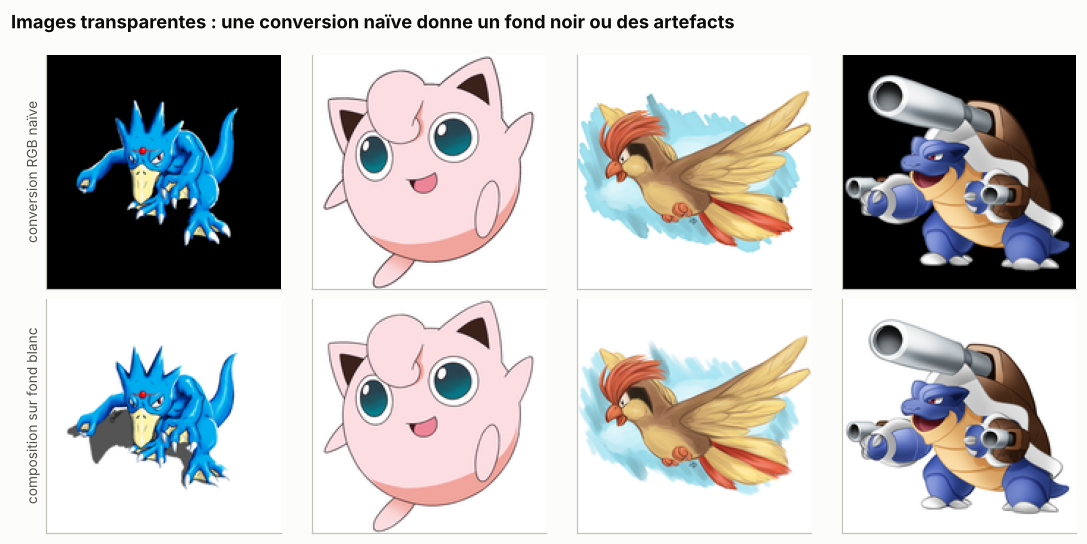

In [6]:
# Pourquoi composer la transparence sur un fond blanc ?
ex = lisibles[lisibles["transparency"]].sample(4, random_state=RANDOM_STATE)
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for k, p in enumerate(ex["path"]):
    im = Image.open(ROOT_DIR / "data" / "images" / p)
    if getattr(im, "n_frames", 1) > 1:
        im.seek(0)
    axes[0, k].imshow(to_square(im.convert("RGB"), 160))          # conversion naïve
    axes[1, k].imshow(to_square(load_rgb(ROOT_DIR / "data" / "images" / p), 160))
    for a in axes[:, k]:
        a.set_xticks([]); a.set_yticks([]); a.grid(False)
axes[0, 0].set_ylabel("conversion RGB naïve", fontsize=9)
axes[1, 0].set_ylabel("composition sur fond blanc", fontsize=9)
fig.suptitle("Images transparentes : une conversion naïve donne un fond noir ou des artefacts",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save_fig(fig, "n2_01_transparence")
plt.show()

**Lecture**

- **3 fichiers sont inutilisables** : un `desktop.ini` (fichier système Windows), un dessin vectoriel `.svg` et un PNG corrompu, dont l'en-tête est invalide.
- **Les formats sont très variés.** On trouve du JPEG, du PNG (RGB, RGBA ou à palette), des GIF dont certains animés, quelques BMP et images en niveaux de gris. Environ **300 fichiers ont une extension trompeuse**, par exemple un `.png` qui est en fait un JPEG. On se fie donc au **format réel** lu par Pillow, jamais à l'extension.
- **Les tailles vont de 42 à 10 000 pixels de côté.** On ramène toutes les images à **224 × 224**, la taille d'entrée des réseaux pré-entraînés sur ImageNet. Pour cela, on **complète** l'image en carré avec du blanc **sans la déformer**, puis on la redimensionne. On évite le recadrage, qui pourrait couper le Pokémon.
- **Environ 4 600 images sont transparentes.** Une conversion RGB naïve rend le fond **noir** ou fait apparaître des artefacts de couleur, et le modèle risquerait d'apprendre que « fond noir = image PNG ». On compose donc sur **fond blanc**, ce qui correspond au fond le plus fréquent des artworks.
- **GIF animés** : on garde la première image.
- **Tout le prétraitement est fait par une seule fonction** (`load_rgb` puis `to_square`), réutilisée telle quelle par l'appli. C'est la même logique que le `Pipeline` du niveau 1 : on évite tout écart entre l'entraînement et l'utilisation réelle.

### 0.4 Doublons et quasi-doublons

**Pourquoi c'est crucial.** Si une même image, ou une version à peine recadrée, se retrouve à la fois dans le train et dans le test, le modèle sera évalué sur des images **déjà vues**. Le score sera trop optimiste : c'est une **fuite de données**.

**Deux empreintes**

- **MD5 du fichier** : deux fichiers identiques octet par octet sont des **doublons exacts**.
- **Hash perceptuel (pHash)** : l'image est réduite et passée en niveaux de gris. On calcule une **transformée en cosinus discrète** (DCT, la même que pour la compression JPEG), et on garde les basses fréquences, c'est-à-dire la structure globale de l'image. Chaque coefficient est comparé à la médiane pour former 64 bits. Deux images **visuellement proches** ont des hash proches, même si l'une est redimensionnée, recompressée ou légèrement retouchée. La proximité se mesure par la **distance de Hamming**, le nombre de bits différents sur 64.

**Choix des seuils.** Pour chaque image, on calcule sa distance minimale à une image **de la même espèce** et à une image **d'une autre espèce**. Des distances très faibles entre espèces différentes signalent soit une **erreur d'étiquette**, soit une image peu informative.

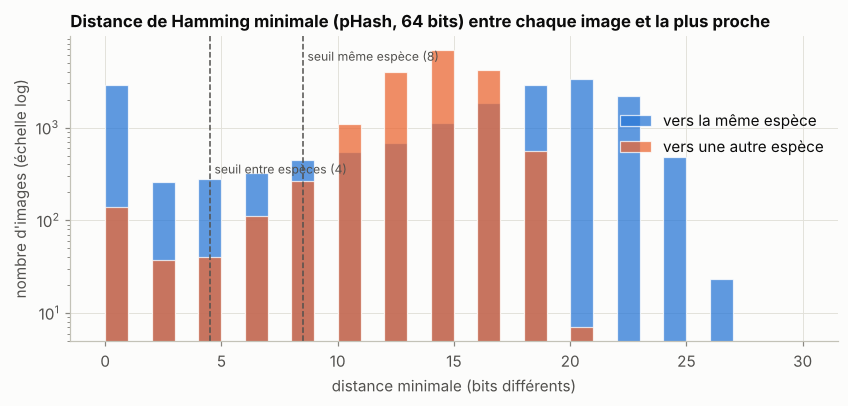

Doublons exacts (même espèce, d = 0) : 2886 images | même image dans 2 espèces (d = 0) : 140


In [7]:
cand = index[~index["motif"].fillna("").str.startswith(("illisible", "image vide", "dossier"))].reset_index(drop=True)
meme, autre = min_hamming_to_others(cand["phash"].tolist(), cand["pokedex_number"].to_numpy())
fig, ax = plt.subplots(figsize=(9, 3.6))
bins = np.arange(0, 31)
ax.hist(np.clip(meme, 0, 30), bins=bins, color=SERIES[0], alpha=0.75, label="vers la même espèce",
        edgecolor="white", linewidth=0.8)
ax.hist(np.clip(autre, 0, 30), bins=bins, color=SERIES[1], alpha=0.75, label="vers une autre espèce",
        edgecolor="white", linewidth=0.8)
for s, lab, y in [(SEUIL_AUTRE_ESPECE, "seuil entre espèces", 0.55), (SEUIL_MEME_ESPECE, "seuil même espèce", 0.92)]:
    ax.axvline(s + 0.5, color=INK_2, ls="--", lw=1)
    ax.text(s + 0.7, y, f"{lab} ({s})", fontsize=8, color=INK_2, transform=ax.get_xaxis_transform())
ax.set_yscale("log")
ax.set(title="Distance de Hamming minimale (pHash, 64 bits) entre chaque image et la plus proche",
       xlabel="distance minimale (bits différents)", ylabel="nombre d'images (échelle log)")
ax.legend(loc="upper right", bbox_to_anchor=(1, 0.8))
save_fig(fig, "n2_02_distances_phash")
plt.show()
print(f"Doublons exacts (même espèce, d = 0) : {(meme == 0).sum()} images "
      f"| même image dans 2 espèces (d = 0) : {(autre == 0).sum()}")

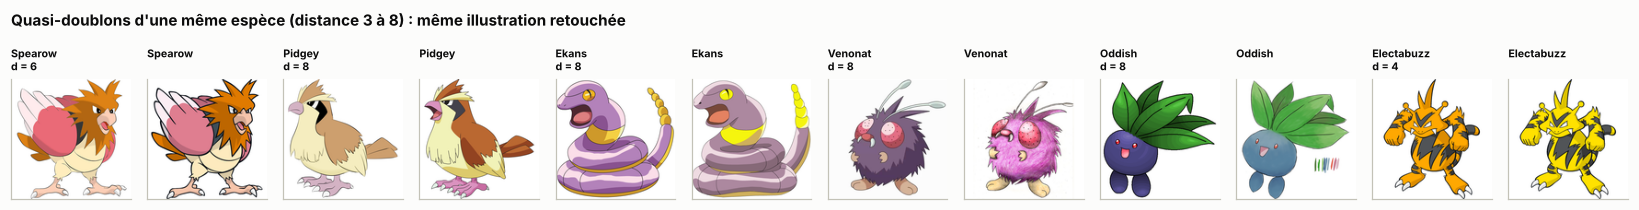

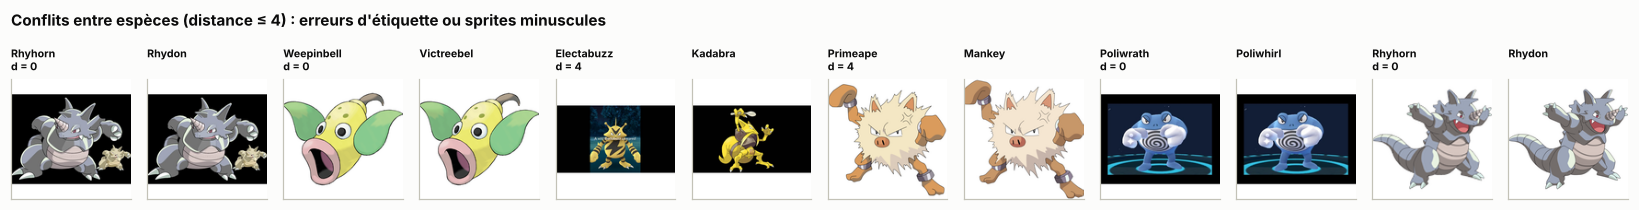

In [8]:
def planche(paires, titre, nom, n=6, S=130):
    fig, axes = plt.subplots(1, 2 * n, figsize=(2 * n * 1.25, 2.1))
    for k, (a, b, d) in enumerate(paires[:n]):
        for j, idx in enumerate((a, b)):
            ax = axes[2 * k + j]
            ax.imshow(to_square(load_rgb(ROOT_DIR / "data" / "images" / cand.loc[idx, "path"]), S))
            ax.set_title(f"{cand.loc[idx, 'folder'][:10]}" + (f"\nd = {d}" if j == 0 else "\n"), fontsize=7)
            ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    fig.suptitle(titre, x=0.01, ha="left", fontweight="bold", fontsize=10)
    fig.tight_layout()
    save_fig(fig, nom)
    plt.show()

h = np.array([int(x, 16) for x in cand["phash"]], dtype=np.uint64)
sp = cand["pokedex_number"].to_numpy()
rng = np.random.default_rng(RANDOM_STATE)

def exemples(meme_espece, lo, hi, n=6):
    out = []
    for i in rng.permutation(len(h)):
        d = np.bitwise_count(h ^ h[i]).astype(int); d[i] = 99
        m = (d >= lo) & (d <= hi) & ((sp == sp[i]) if meme_espece else (sp != sp[i]))
        if m.any():
            out.append((i, int(np.nonzero(m)[0][0]), int(d[np.nonzero(m)[0][0]])))
        if len(out) >= n:
            break
    return out

planche(exemples(True, 3, 8), f"Quasi-doublons d'une même espèce (distance 3 à {SEUIL_MEME_ESPECE}) : même illustration retouchée",
        "n2_03_quasi_doublons")
planche(exemples(False, 0, SEUIL_AUTRE_ESPECE), f"Conflits entre espèces (distance ≤ {SEUIL_AUTRE_ESPECE}) : erreurs d'étiquette ou sprites minuscules",
        "n2_04_conflits_especes")

**Lecture et règles retenues**

- **Entre images de la même espèce**, les distances faibles (≤ 8) correspondent presque toujours à la **même illustration** recadrée, recompressée, recolorée ou légèrement retouchée (voir la première planche).
  - **Règle :** on regroupe ces quasi-doublons (seuil de 8 bits, groupes = composantes connexes par union-find) et on **ne garde que la plus grande image de chaque groupe**.
  - Ainsi, chaque illustration n'apparaît **qu'une fois** dans tout le dataset, et ne peut pas se retrouver à la fois dans le train et dans le test.
- **Entre espèces différentes**, une distance très faible (≤ 4) révèle deux situations (voir la seconde planche) :
  - de **vraies erreurs d'étiquette** : la même image de Roucool rangée dans Roucoups, la même image de Férosinge rangée dans Colossinge, des images de **lignées d'évolution** entières ;
  - de **fausses alertes** : des sprites minuscules sur un grand fond blanc, ou des cartes Pokémon à la mise en page identique, dont les pHash se ressemblent.

  **Règle prudente :** on retire **toutes** les images concernées. On ne peut pas savoir laquelle des deux étiquettes est juste, et une image minuscule apporte de toute façon peu d'information.
- **Au-delà de 9 ou 10 bits**, les distances entre espèces différentes deviennent fréquentes et relèvent du hasard. Le hash ne permet plus de conclure, et on s'arrête donc à ces seuils prudents.

### 0.5 Bilan du nettoyage

In [9]:
index["décision"] = index["motif"].fillna("").replace("", "gardée")
index.loc[index["décision"].str.startswith("illisible"), "décision"] = "illisible / non image"
bilan = index["décision"].value_counts().rename("fichiers").to_frame()
bilan["%"] = (bilan["fichiers"] / len(index) * 100).round(1)
display(bilan)

garde = index[index["garde"]].copy()
print(f"Dataset final : {len(garde)} images, {garde['pokedex_number'].nunique()} espèces "
      f"({len(garde) / len(index):.0%} des fichiers d'origine)")

,fichiers,%
décision,,
gardée,14715,85.2
doublon exact,1174,6.8
quasi-doublon,1153,6.7
conflit entre espèces,217,1.3
illisible / non image,3,0.0
image vide,1,0.0


Dataset final : 14715 images, 142 espèces (85% des fichiers d'origine)


### 0.6 Exploration du dataset nettoyé

Images par Pokémon : min 56, médiane 103, max 165 (rapport max/min = 2.9)


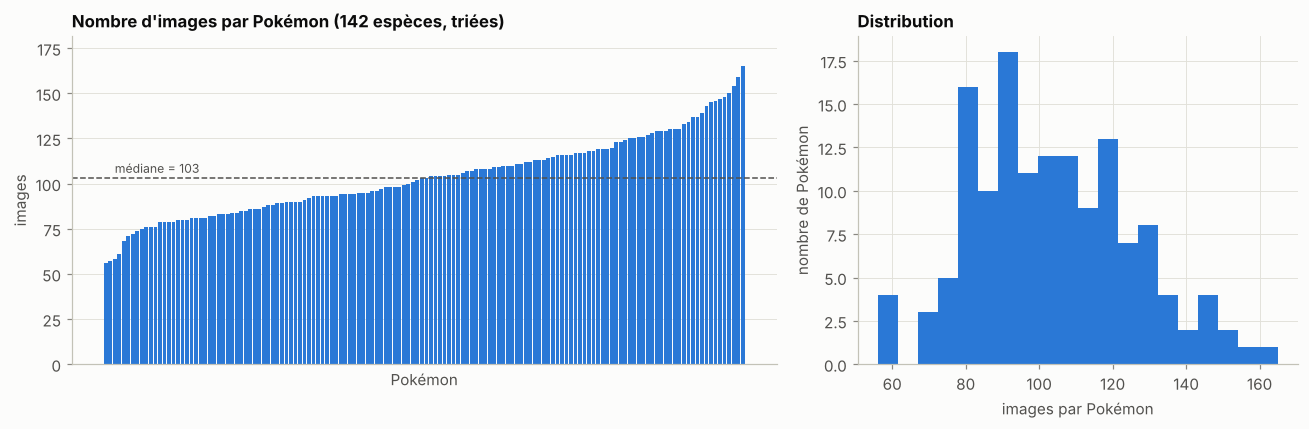

Les moins représentés : Seel (56), Abra (57), Electrode (58), Seaking (61), Gloom (68), Slowbro (71)
Les plus représentés  : Psyduck (165), Pikachu (159), Jigglypuff (154), Scyther (150), Vaporeon (148), Snorlax (147)


In [10]:
par_poke = garde.groupby(["pokedex_number", "name"]).size().rename("images").reset_index()
print(f"Images par Pokémon : min {par_poke['images'].min()}, médiane {par_poke['images'].median():.0f}, "
      f"max {par_poke['images'].max()} (rapport max/min = {par_poke['images'].max() / par_poke['images'].min():.1f})")
fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw=dict(width_ratios=[1.6, 1]))
ax = axes[0]
p = par_poke.sort_values("images")
ax.bar(range(len(p)), p["images"], color=SERIES[0], width=0.85)
ax.axhline(p["images"].median(), color=INK_2, ls="--", lw=1)
ax.text(2, p["images"].median() + 3, f"médiane = {p['images'].median():.0f}", fontsize=8, color=INK_2)
ax.set(title="Nombre d'images par Pokémon (142 espèces, triées)", xlabel="Pokémon", ylabel="images",
       ylim=(0, p["images"].max() * 1.1))
ax.set_xticks([])
ax.grid(axis="x", visible=False)

ax = axes[1]
ax.hist(p["images"], bins=20, color=SERIES[0], edgecolor="white")
ax.set(title="Distribution", xlabel="images par Pokémon", ylabel="nombre de Pokémon")
fig.tight_layout()
save_fig(fig, "n2_05_images_par_pokemon")
plt.show()
print("Les moins représentés :", ", ".join(f"{n} ({k})" for n, k in p.head(6)[["name", "images"]].values))
print("Les plus représentés  :", ", ".join(f"{n} ({k})" for n, k in p.tail(6)[::-1][["name", "images"]].values))

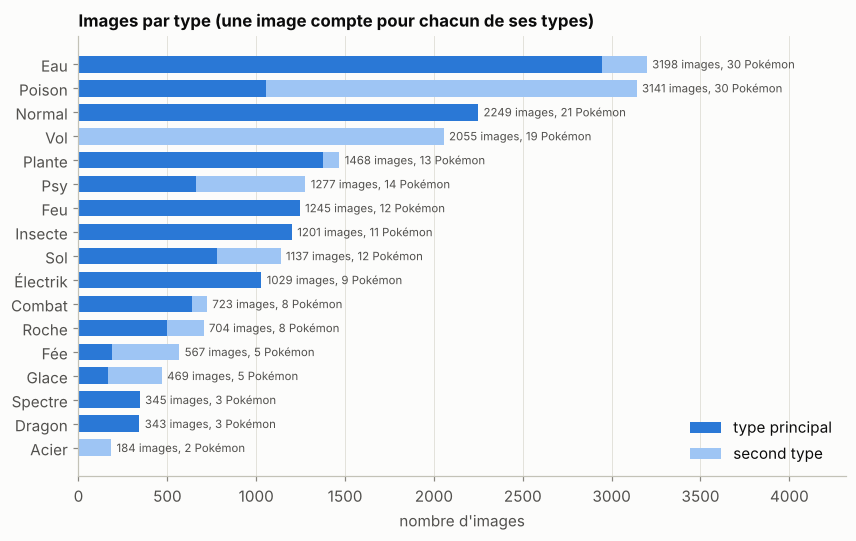

Pokémon à deux types : 63 sur 142 (44%) | images de Pokémon à deux types : 45%
Types absents en type principal mais présents en second type : ['Acier', 'Vol']


In [11]:
# Par type : une image compte pour chacun de ses types (problème multi-label)
lignes = []
for t in sorted(set(garde["type1"]) | set(garde["type2"]) - {"aucun"}):
    m1, m2 = garde["type1"] == t, garde["type2"] == t
    pokes = garde.loc[m1 | m2, "pokedex_number"].nunique()
    lignes.append({"type": TYPE_FR[t], "images (type 1)": int(m1.sum()), "images (type 2)": int(m2.sum()),
                   "images au total": int((m1 | m2).sum()), "Pokémon": pokes})
par_type = pd.DataFrame(lignes).set_index("type").sort_values("images au total")

fig, ax = plt.subplots(figsize=(9, 5.2))
ax.barh(par_type.index, par_type["images (type 1)"], color=SERIES[0], height=0.7, label="type principal")
ax.barh(par_type.index, par_type["images (type 2)"], left=par_type["images (type 1)"], color="#9ec5f4",
        height=0.7, label="second type")
for i, (tot, n) in enumerate(zip(par_type["images au total"], par_type["Pokémon"])):
    ax.text(tot + 30, i, f"{tot} images, {n} Pokémon", va="center", fontsize=7.5, color=INK_2)
ax.set(title="Images par type (une image compte pour chacun de ses types)", xlabel="nombre d'images",
       xlim=(0, par_type["images au total"].max() * 1.35))
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
save_fig(fig, "n2_06_images_par_type")
plt.show()

n_types = (garde.drop_duplicates("pokedex_number")["type2"] != "aucun")
print(f"Pokémon à deux types : {n_types.sum()} sur {len(n_types)} ({n_types.mean():.0%}) "
      f"| images de Pokémon à deux types : {(garde['type2'] != 'aucun').mean():.0%}")
print("Types absents en type principal mais présents en second type :",
      [TYPE_FR[t] for t in set(garde["type2"]) - set(garde["type1"]) - {"aucun"}])

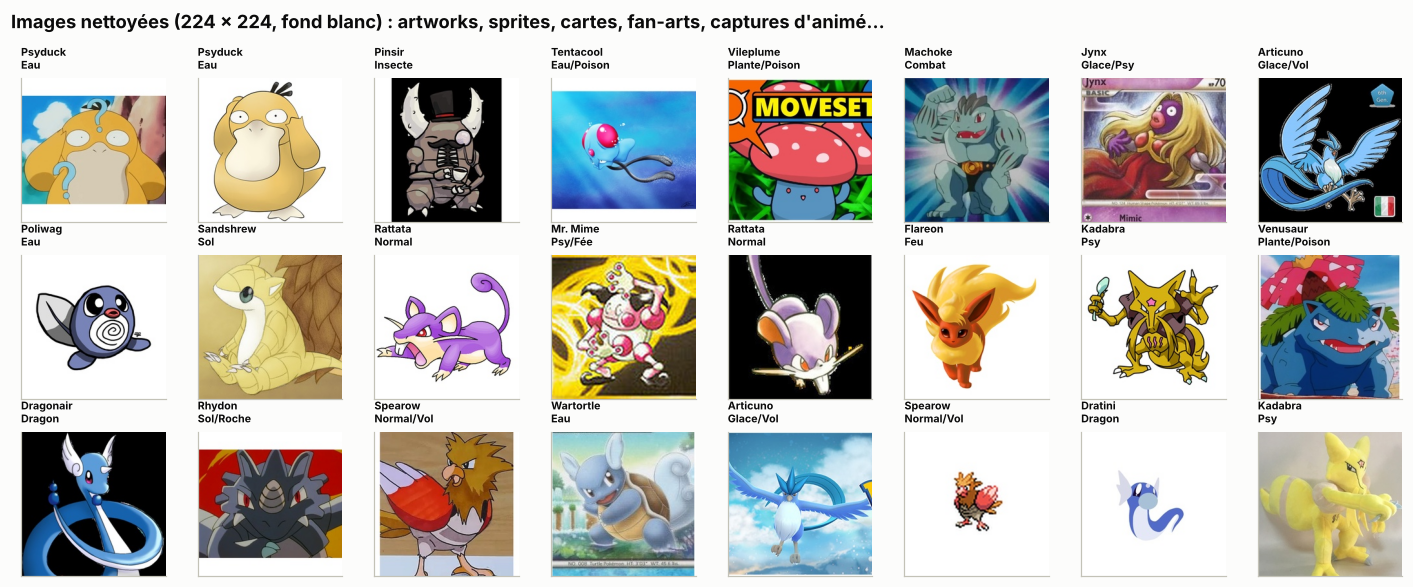

In [12]:
# Exemples d'images nettoyées (ce que verra le modèle)
ex = garde.sample(24, random_state=RANDOM_STATE)
fig, axes = plt.subplots(3, 8, figsize=(13, 5.4))
for ax, (_, r) in zip(axes.flat, ex.iterrows()):
    ax.imshow(Image.open(ROOT_DIR / r["clean_path"]))
    t = TYPE_FR[r["type1"]] + ("/" + TYPE_FR[r["type2"]] if r["type2"] != "aucun" else "")
    ax.set_title(f"{r['name']}\n{t}", fontsize=7)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
fig.suptitle("Images nettoyées (224 × 224, fond blanc) : artworks, sprites, cartes, fan-arts, captures d'animé…",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save_fig(fig, "n2_07_exemples")
plt.show()

**Lecture**

- **Images par Pokémon :** le déséquilibre est **modéré**, avec un rapport d'environ 3 entre le Pokémon le moins représenté (environ 55 images) et le plus représenté (environ 165). Les Pokémon populaires (Pikachu, starters, Mewtwo…) ont plus d'images. Les moins représentés seront probablement plus difficiles à reconnaître, ce que la couverture devra vérifier.
- **Images par type :** le déséquilibre est **fort**. Eau, Poison, Normal et Vol dépassent 2 000 images, tandis qu'Acier, Dragon, Spectre, Glace et Fée en ont moins de 600.
  - En 1ʳᵉ génération, certains types n'existent **qu'en second type** : Vol (Roucool, Nosferapti…) et Acier (Magnéti et Magnéton, Électrik/Acier).
  - Les types rares reposent sur **très peu de Pokémon différents** : 2 pour Acier (Magnéti, Magnéton), 3 pour Dragon et Spectre, 5 pour Fée et Glace. Apprendre le type « Dragon » revient à apprendre Minidraco, Draco et Dracolosse. C'est un défi pour l'approche A sur des Pokémon jamais vus (partie 1).
- **Près de la moitié des Pokémon (44 %) ont deux types**, ce qui confirme la formulation **multi-label**.
- **Les images sont très hétérogènes** : artworks officiels, sprites pixelisés, cartes à jouer, fan-arts, captures d'animé, peluches… C'est **réaliste** pour la caméra du niveau 3, mais difficile. Le fond, le style et le cadrage varient beaucoup.

### 0.7 Synthèse des données

| Étape | Résultat |
|---|---|
| Archive | 17 263 fichiers, 143 dossiers, environ 3 Go |
| Association avec le CSV | 143 dossiers → **142 espèces** (Mr. Mime réparti sur 2 dossiers). **9 Pokémon sans aucune image** |
| Fichiers inutilisables | 3 (desktop.ini, svg, PNG corrompu) + 1 image vide |
| Doublons exacts / quasi-doublons d'une même espèce | retirés, on garde une image par groupe (pHash, seuil de 8 bits) |
| Conflits entre espèces | retirés (pHash, seuil de 4 bits) : erreurs d'étiquette ou sprites minuscules |
| **Dataset final** | **environ 14 700 images**, de 224 × 224, sur fond blanc |
| Étiquettes de type | 14 Pokémon corrigés (types de forme d'Alola dans le CSV) |
| Déséquilibre | modéré par Pokémon (de 56 à 165 images, rapport ≈ 3), **fort par type** |

## 1. Formulation du problème et découpage des données

### 1.1 Un problème multi-label

Un Pokémon a **un ou deux types** : Bulbizarre est Plante **et** Poison. Prédire « le » type avec un softmax obligerait à choisir un seul type, et donc à se tromper à moitié pour 44 % des Pokémon. C'est un problème **multi-label** : chaque image a un **ensemble** d'étiquettes.

**Les 17 types présents.** Les images de 1ʳᵉ génération couvrent 17 types. **Ténèbres n'existe pas** chez les Pokémon de 1ʳᵉ génération (une fois le CSV corrigé, partie 0.2). Une sortie qui n'a jamais d'exemple positif ne peut rien apprendre : on garde donc $K = 17$ sorties au lieu de 18.

**Le modèle.** On utilise une sortie **sigmoïde par type**, $p_k = \sigma(z_k) = \frac{1}{1 + e^{-z_k}}$. Chaque $p_k$ est la probabilité **indépendante** que l'image ait le type $k$. Contrairement au softmax, les $p_k$ **ne somment pas à 1** : on peut avoir à la fois $p_{\text{Plante}} = 0{,}9$ et $p_{\text{Poison}} = 0{,}8$.

**La fonction de coût** est l'entropie croisée binaire (*binary cross-entropy*), moyennée sur les $K$ types :

$$\mathcal{L}(\mathbf{y}, \mathbf{p}) = -\frac{1}{K} \sum_{k=1}^{K} \Big[\, y_k \ln p_k + (1 - y_k) \ln(1 - p_k) \,\Big]$$

C'est la log-loss du niveau 1, appliquée à 17 problèmes binaires en parallèle qui partagent les mêmes couches du réseau.

**La décision.** On prédit le type $k$ si $p_k \geq t_k$. Les seuils $t_k$ seront réglés sur la validation, comme au niveau 1. On ajoute une règle : on prédit **au moins un** type (le plus probable), et **au plus deux**, puisqu'aucun Pokémon n'en a trois.

K = 17 types | 14715 images | types par image en moyenne (cardinalité) : 1.45


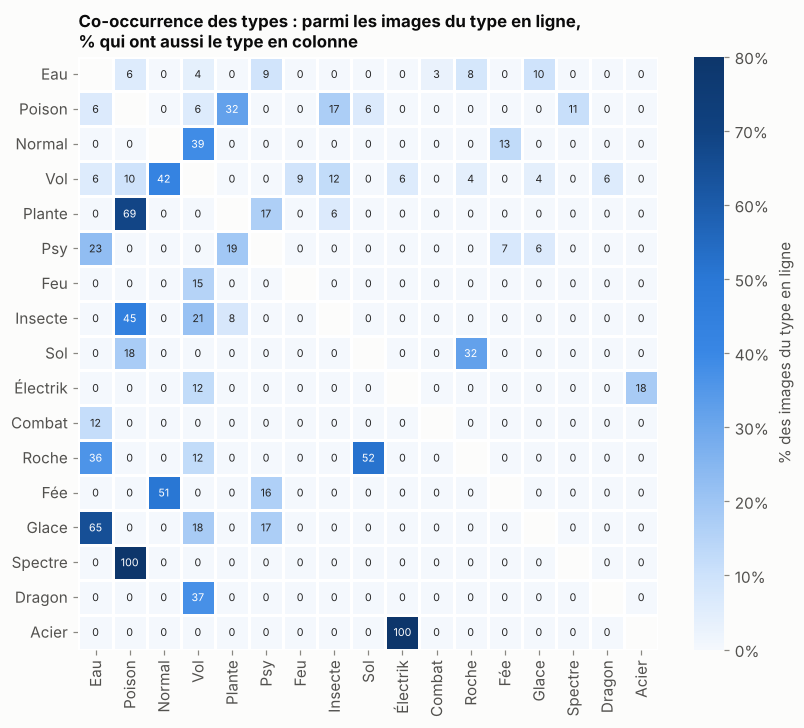

In [13]:
from src.image_utils import TYPES_IMAGES, multilabel_matrix, make_splits, SPLITS_PATH
garde = index[index["garde"]].reset_index(drop=True)
Y = multilabel_matrix(garde)
K = len(TYPES_IMAGES)
print(f"K = {K} types | {len(garde)} images | types par image en moyenne (cardinalité) : {Y.sum(1).mean():.2f}")

co = pd.DataFrame(Y.T @ Y, index=[TYPE_FR[t] for t in TYPES_IMAGES], columns=[TYPE_FR[t] for t in TYPES_IMAGES])
ordre = co.values.diagonal().argsort()[::-1]
co = co.iloc[ordre, ordre]
arr = co.to_numpy() / np.diag(co.to_numpy())[:, None]   # P(type colonne | type ligne)
np.fill_diagonal(arr, np.nan)                        # la diagonale (100 %) n'apporte rien
co_pct = pd.DataFrame(arr, index=co.index, columns=co.columns)
import seaborn as sns
from src.viz import CMAP_SEQ
fig, ax = plt.subplots(figsize=(8.5, 7))
sns.heatmap(co_pct, cmap=CMAP_SEQ, vmin=0, vmax=0.8, annot=(co_pct * 100).round(0), fmt=".0f",
            annot_kws=dict(fontsize=7), linewidths=0.8, linecolor="white",
            cbar_kws=dict(label="% des images du type en ligne", format=plt.matplotlib.ticker.PercentFormatter(1)), ax=ax)
ax.set(title="Co-occurrence des types : parmi les images du type en ligne,\n% qui ont aussi le type en colonne",
       xlabel="", ylabel="")
ax.grid(False)
save_fig(fig, "n2_08_cooccurrence_types")
plt.show()

**Lecture.** Les types ne sont **pas indépendants**, et certaines associations sont totales :
- **Acier → Électrik** (100 % : Magnéti et Magnéton) et **Spectre → Poison** (100 % : Fantominus, Spectrum, Ectoplasma) ;
- **Plante → Poison** (69 %), **Glace → Eau** (65 %), **Roche → Sol** (52 %), **Fée → Normal** (51 % : Rondoudou, Grodoudou), **Vol → Normal** (42 % : Roucool, Doduo…).

Un réseau à 17 sigmoïdes partage les mêmes couches pour tous les types. Il pourra donc apprendre ces associations **implicitement**. Mais elles reposent sur très peu d'espèces : le réseau risque d'en déduire de fausses règles, comme « un Pokémon métallique est Électrik » ou « un fantôme est Poison ». C'est vrai en 1ʳᵉ génération, mais faux en général.

### 1.2 Deux approches à comparer

| | **(A) Types en direct** (multi-label) | **(B) Espèce, puis types** (classification) |
|---|---|---|
| Sorties | 17 sigmoïdes, une par type | 142 classes en **softmax**, une par espèce |
| Coût | entropie croisée **binaire** | entropie croisée **catégorielle** $-\ln p_{\text{vraie espèce}}$ |
| Types prédits | directement | on lit le ou les types de l'espèce prédite dans `pokemon.csv` |
| Avantage | **généralise** à un Pokémon jamais vu : le réseau apprend des indices visuels de type (couleur bleue → Eau, flammes → Feu, ailes → Vol) | souvent **plus précise** sur les Pokémon connus : reconnaître Pikachu est plus « concret » que reconnaître l'idée d'Électrik. Elle donne **en plus** le nom du Pokémon (indispensable pour la caméra du niveau 3) |
| Limite | doit apprendre des concepts abstraits à partir de peu d'espèces (Dragon = 3 Pokémon) | **ne peut rien dire** d'un Pokémon absent du train, comme les 9 Pokémon sans image. Une espèce mal reconnue donne **ses deux types** faux d'un coup |

**On peut aussi déduire des probabilités de types à partir de (B).** Si le modèle donne la distribution $P(s \mid \text{image})$ sur les espèces, on en tire :

$$P(\text{type } k \mid \text{image}) = \sum_{s \,:\, k \,\in\, \text{types}(s)} P(s \mid \text{image})$$

C'est la somme des probabilités des espèces qui ont ce type. On peut ainsi évaluer A et B **avec exactement les mêmes métriques multi-label**, ce qui rend la comparaison équitable.

### 1.3 Découpage train / validation / test (70 / 15 / 15), stratifié par Pokémon

- **Rôle des trois parties :**
  - le **train** sert à entraîner ;
  - la **validation** sert à choisir les hyperparamètres, à arrêter l'entraînement au bon moment (*early stopping*) et à régler les seuils ;
  - le **test** est mis **sous clé** jusqu'à l'évaluation finale (partie 5), comme au niveau 1.
- **Stratification par Pokémon :** chaque espèce garde environ 70 % de ses images dans le train, 15 % dans la validation et 15 % dans le test. Les 142 espèces sont donc toutes représentées partout, même les moins fournies : Otaria n'a que 56 images.
- **Pas de fuite par doublons :** les doublons et quasi-doublons ont été retirés en partie 0. Une même illustration ne peut donc pas être à la fois en train et en test. On le **vérifie** ci-dessous avec un seuil plus large.

In [14]:
splits = make_splits(garde, seed=RANDOM_STATE)
splits.to_csv(SPLITS_PATH, index=False)
Ys = multilabel_matrix(splits)

taille = splits["split"].value_counts().reindex(["train", "val", "test"])
display(pd.DataFrame({"images": taille, "%": (taille / len(splits) * 100).round(1),
                      "espèces": splits.groupby("split")["pokedex_number"].nunique().reindex(taille.index)}).T)

# Vérification : chaque espèce a bien ~70/15/15
prop = pd.crosstab(splits["pokedex_number"], splits["split"], normalize="index")[["train", "val", "test"]]
print("Part du train par espèce : min {:.0%}, max {:.0%} | espèces sans image de test : {}".format(
      prop["train"].min(), prop["train"].max(), (prop["test"] == 0).sum()))

# Vérification : même proportion de chaque type dans les 3 parties
prev = pd.DataFrame({s: Ys[(splits["split"] == s).values].mean(0) for s in ["train", "val", "test"]},
                    index=[TYPE_FR[t] for t in TYPES_IMAGES])
print(f"Écart maximal de fréquence d'un type entre train et test : {(prev['train'] - prev['test']).abs().max():.3f}")

split,train,val,test
images,10300.0,2207.0,2208.0
%,70.0,15.0,15.0
espèces,142.0,142.0,142.0


Part du train par espèce : min 69%, max 71% | espèces sans image de test : 0
Écart maximal de fréquence d'un type entre train et test : 0.001


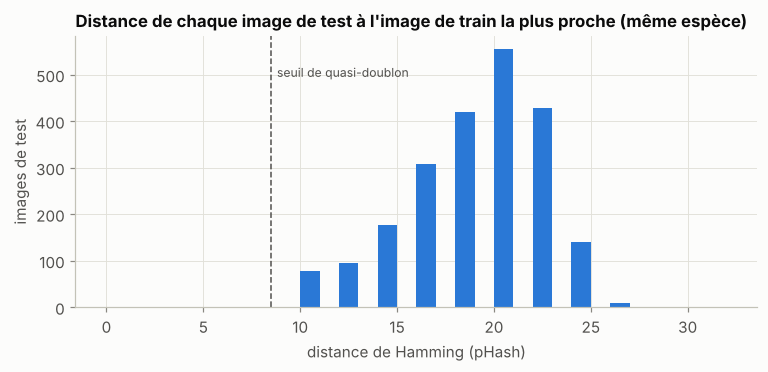

Images de test à distance ≤ 8 d'une image de train : 0 | à distance ≤ 10 : 3.5% | médiane : 20 bits


In [15]:
# Fuite résiduelle ? Distance pHash minimale entre chaque image de TEST et le TRAIN (même espèce)
ph = {s: np.array([int(x, 16) for x in garde.loc[(splits["split"] == s).values, "phash"]], dtype=np.uint64)
      for s in ["train", "test"]}
esp = {s: splits.loc[splits["split"] == s, "pokedex_number"].to_numpy() for s in ["train", "test"]}
dmin = np.array([np.bitwise_count(ph["train"][esp["train"] == e] ^ h).min()
                 for h, e in zip(ph["test"], esp["test"])])
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(dmin, bins=np.arange(0, 33), color=SERIES[0], edgecolor="white")
ax.axvline(SEUIL_MEME_ESPECE + 0.5, color=INK_2, ls="--", lw=1)
ax.text(SEUIL_MEME_ESPECE + 0.8, ax.get_ylim()[1] * 0.85, "seuil de quasi-doublon", fontsize=8, color=INK_2)
ax.set(title="Distance de chaque image de test à l'image de train la plus proche (même espèce)",
       xlabel="distance de Hamming (pHash)", ylabel="images de test")
save_fig(fig, "n2_09_fuite_residuelle")
plt.show()
print(f"Images de test à distance ≤ {SEUIL_MEME_ESPECE} d'une image de train : {(dmin <= SEUIL_MEME_ESPECE).sum()} "
      f"| à distance ≤ 10 : {(dmin <= 10).mean():.1%} | médiane : {np.median(dmin):.0f} bits")

**Lecture**

- **La stratification est bien respectée :**
  - chaque espèce a entre 69 et 71 % de ses images dans le train, et au moins quelques images de test ;
  - chaque type a la même fréquence dans le train, la validation et le test, à moins de 1 point près.
- **Il n'y a pas de fuite résiduelle par quasi-doublons.** Par construction, **aucune** image de test n'est à moins de 8 bits d'une image de train de la même espèce. Seules 3,5 % des images de test sont à 9 ou 10 bits, et la distance médiane est de 20 bits, l'ordre de grandeur de deux **illustrations différentes**. Les images de test sont donc de **nouvelles images** de Pokémon connus, et non des copies retouchées d'images d'entraînement.
- **Limite assumée :** un même dessinateur ou une même série de sprites peut produire des images **différentes mais de même style** (même fond, même trait). Le hash ne les détecte pas comme doublons. Le modèle pourrait s'appuyer en partie sur le style, ce qu'on surveillera avec Grad-CAM (partie 5).

### 1.4 Test de généralisation : des Pokémon jamais vus (validation croisée groupée par espèce)

Le découpage 1.3 répond à la question : **« le modèle reconnaît-il de nouvelles images de Pokémon qu'il connaît ? »**

Le sujet insiste aussi sur la capacité à **généraliser**. On pose donc une seconde question, plus difficile : **« le modèle devine-t-il les types d'un Pokémon qu'il n'a jamais vu ? »** C'est exactement la situation des 9 Pokémon sans image, et de toute future génération.

**Protocole.** Une `StratifiedGroupKFold` à 5 plis :
- **groupée par espèce** : toutes les images d'un Pokémon sont dans le **même** pli ;
- **stratifiée sur le type principal**, pour que chaque pli contienne des Pokémon de types variés.

On entraîne sur 4 plis et on évalue sur le 5ᵉ : le modèle n'a **jamais vu** les environ 28 espèces du pli évalué. Ce protocole n'a de sens **que pour l'approche A**. L'approche B ne peut pas prédire une espèce absente de ses classes : elle aurait 0 % par construction.

In [16]:
lignes = []
for k in range(5):
    te = splits["fold"] == k
    t_tr = set(TYPES_IMAGES[j] for j in np.nonzero(Ys[~te.values].sum(0))[0])
    t_te = set(TYPES_IMAGES[j] for j in np.nonzero(Ys[te.values].sum(0))[0])
    noms = splits.loc[te].drop_duplicates("pokedex_number")["name"].tolist()
    lignes.append({"pli": k, "images": int(te.sum()), "espèces": len(noms),
                   "types présents": len(t_te), "types du pli absents du reste": sorted(TYPE_FR[t] for t in t_te - t_tr) or "-",
                   "exemples d'espèces": ", ".join(noms[:6]) + "…"})
display(pd.DataFrame(lignes).set_index("pli"))

# Les types les plus fragiles dans ce protocole : très peu d'espèces
esp_par_type = pd.Series({TYPE_FR[t]: splits.loc[Ys[:, k] == 1, "pokedex_number"].nunique()
                          for k, t in enumerate(TYPES_IMAGES)}).sort_values()
print("Nombre d'espèces par type :", esp_par_type.to_dict())

,images,espèces,types présents,types du pli absents du reste,exemples d'espèces
pli,,,,,
0,2993,29,16,-,"Alakazam, Arbok, Articuno, Bulbasaur, Butterfree, Cubone…"
1,2978,29,14,-,"Arcanine, Charizard, Charmeleon, Diglett, Ditto, Dodrio…"
2,2753,26,15,-,"Abra, Blastoise, Caterpie, Chansey, Charmander, Dragonite…"
3,3143,31,16,-,"Beedrill, Clefairy, Cloyster, Dewgong, Dragonair, Electrode…"
4,2848,27,14,-,"Aerodactyl, Bellsprout, Clefable, Doduo, Dratini, Drowzee…"


Nombre d'espèces par type : {'Acier': 2, 'Dragon': 3, 'Spectre': 3, 'Fée': 5, 'Glace': 5, 'Roche': 8, 'Combat': 8, 'Électrik': 9, 'Insecte': 11, 'Feu': 12, 'Sol': 12, 'Plante': 13, 'Psy': 14, 'Vol': 19, 'Normal': 21, 'Poison': 30, 'Eau': 30}


**Lecture**

- **Chaque pli contient environ 28 espèces et environ 3 000 images.** Aucun type du pli évalué n'est absent du reste des données : le modèle a toujours vu au moins une autre espèce de chaque type.
- **Mais certains types reposent sur très peu d'espèces.** Pour Acier (2 espèces) ou Dragon et Spectre (3), quand une espèce est mise de côté, il n'en reste que 1 ou 2 pour apprendre le type. Pour Spectre, par exemple, il faudra reconnaître Fantominus à partir de Spectrum et Ectoplasma, ce qui reste plausible puisqu'il s'agit d'une même lignée. Pour Acier, Magnéton devra être reconnu grâce à Magnéti seul. **Il faut s'attendre à des scores bien plus faibles qu'en 1.3**, et très inégaux selon les types.
- **Les deux protocoles se complètent pour le rapport :**
  - **1.3** (Pokémon connus) mesure la qualité d'un **Pokédex** : reconnaître les 142 espèces du jeu de données ;
  - **1.4** (Pokémon inconnus) mesure la **généralisation** du concept de type.

### 1.5 Synthèse

| Élément | Choix |
|---|---|
| Sorties | **17 types** (Ténèbres absent en Gen 1), sigmoïde + entropie croisée binaire (A) ; **142 espèces**, softmax + entropie croisée (B) |
| Décision multi-label | seuil par type réglé sur la validation, au moins 1 et au plus 2 types |
| Comparaison A / B | mêmes métriques multi-label : les types de B sont déduits par $P(k) = \sum_{s \ni k} P(s)$ |
| Découpage principal | 70 / 15 / 15 stratifié par Pokémon (10 300 / 2 207 / 2 208 images). Test sous clé. Aucune fuite par quasi-doublon |
| Généralisation | 5 plis groupés par espèce (environ 28 Pokémon inconnus par pli), **approche A seulement** |
| Fichier | `data/images_splits.csv` (versionné) : `split` et `fold` de chaque image, réutilisés par toutes les étapes suivantes |

## 2. Référence classique : caractéristiques choisies à la main + modèles du niveau 1

Avant les réseaux de neurones, on établit une **référence** avec des caractéristiques **conçues à la main**. Les modèles sont ceux du niveau 1 : régression logistique, SVM et Random Forest. Elle répond à une question simple : **un réseau de neurones est-il vraiment nécessaire ?** Elle fixe aussi le niveau à battre.

### 2.1 Les caractéristiques : couleur + forme

1. **Histogramme de couleurs HSV** (12 teintes × 4 saturations × 4 valeurs = **192 valeurs**).
   - L'espace **HSV** sépare la **teinte** (H : rouge, bleu…), la **saturation** (S : vif ou terne) et la **valeur** (V : clair ou sombre). Il est plus proche de la perception humaine que RGB.
   - On ne compte **que les pixels du Pokémon** : les pixels presque blancs, qui forment le fond, sont exclus. Sans ce masque, le fond blanc dominerait tous les histogrammes.
   - **Ce que capte cette caractéristique :** « beaucoup de bleu → Eau », « jaune → Électrik », « orange/rouge → Feu ».
2. **HOG**, histogramme de gradients orientés (**1 764 valeurs**).
   - L'image est passée en niveaux de gris, en 64 × 64, puis découpée en cellules de 8 × 8 pixels.
   - Dans chaque cellule, on calcule la direction du gradient d'intensité $\theta = \arctan(\partial_y I / \partial_x I)$ pour chaque pixel. On construit l'histogramme de ces directions sur **9 orientations**, en pondérant par la norme du gradient $\|\nabla I\|$.
   - Les histogrammes sont normalisés par blocs de 2 × 2 cellules, pour résister aux variations de contraste.
   - **Ce que capte cette caractéristique :** la **forme** et les **contours** (silhouette, ailes, oreilles).

Au total, chaque image est décrite par **1 956 nombres**. On perd tout le reste : textures fines, position relative des parties, contexte.

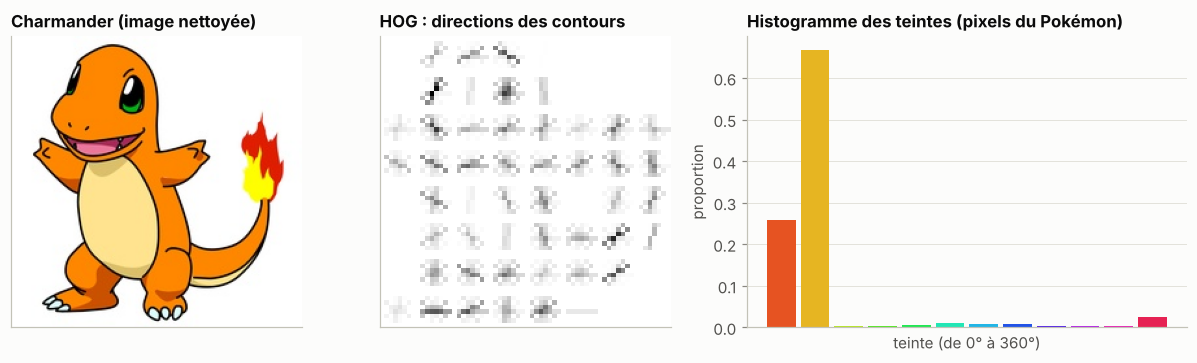

Caractéristiques : 14715 images × 1956 valeurs (1 s)


In [17]:
import time
from skimage.feature import hog
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.multiclass import OneVsRestClassifier
from sklearn.model_selection import StratifiedGroupKFold
from src.image_utils import (classic_features, color_histogram, decide_types, multilabel_scores,
                             species_scores, coverage, HIST_BINS, HOG_SIZE)

warnings.filterwarnings("ignore", category=FutureWarning)     # SVC(probability=True), voir 2.3

# Illustration sur une image
r = splits[splits["name"] == "Charmander"].iloc[3]
img = Image.open(ROOT_DIR / r["clean_path"]).convert("RGB")
g = np.asarray(img.convert("L").resize((HOG_SIZE, HOG_SIZE)), dtype=np.float32) / 255
_, hog_img = hog(g, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2), visualize=True)
h = color_histogram(img).reshape(HIST_BINS).sum(axis=(1, 2))        # marginale sur la teinte

fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), gridspec_kw=dict(width_ratios=[1, 1, 1.5]))
axes[0].imshow(img); axes[0].set_title(f"{r['name']} (image nettoyée)")
axes[1].imshow(hog_img, cmap="gray_r"); axes[1].set_title("HOG : directions des contours")
import colorsys
couleurs = [colorsys.hsv_to_rgb((k + 0.5) / HIST_BINS[0], 0.85, 0.9) for k in range(HIST_BINS[0])]
axes[2].bar(range(HIST_BINS[0]), h, color=couleurs, width=0.85)
axes[2].set(title="Histogramme des teintes (pixels du Pokémon)", xlabel="teinte (de 0° à 360°)", ylabel="proportion")
axes[2].set_xticks([])
for a in axes[:2]:
    a.set_xticks([]); a.set_yticks([]); a.grid(False)
fig.tight_layout()
save_fig(fig, "n2_10_caracteristiques_classiques")
plt.show()

t0 = time.time()
X = classic_features(splits["clean_path"])            # mis en cache dans data/cache/
print(f"Caractéristiques : {X.shape[0]} images × {X.shape[1]} valeurs ({time.time() - t0:.0f} s)")
sp = splits["pokedex_number"].to_numpy()
tr, va = (splits["split"] == "train").to_numpy(), (splits["split"] == "val").to_numpy()
table_types = pokemon[["pokedex_number", "type1", "type2"]]

### 2.2 Protocole et métriques

- **Entraînement sur le train, évaluation sur la validation.** Le test reste sous clé jusqu'à la partie 5. Le prétraitement est dans un `Pipeline` : standardisation, puis éventuellement ACP pour le SVM.
- **Les mêmes métriques pour toutes les approches :**

| Métrique | Définition |
|---|---|
| **F1 micro** | F1 calculé en cumulant toutes les décisions (image, type) : **dominé par les types fréquents** |
| **F1 macro** | moyenne des F1 **par type** : chaque type compte autant (Acier autant qu'Eau) |
| **Hamming loss** | part des cases (image, type) mal prédites, sur 17 cases par image. Plus bas = mieux |
| **Exact match** | part des images dont l'**ensemble** des types est exactement le bon (les deux types justes) |
| **≥ 1 type correct** | au moins un des types prédits est un vrai type de l'image |
| **Couverture** | exact match calculé **pour chaque Pokémon**, puis part des Pokémon qui dépassent 50 %, 70 % et 90 % |

- **Pour l'approche B**, on ajoute top-1, top-5 et F1 macro sur les 142 espèces. Les types prédits sont **ceux de l'espèce la plus probable**.
- **Pour l'approche A**, un type est prédit si $p_k \geq 0{,}5$, avec au moins 1 type et au plus 2. Le réglage fin des seuils viendra en partie 5.
- **Références sans apprentissage :**
  - pour **A** : toujours prédire le type le plus fréquent du train (Eau) ;
  - pour **B** : toujours prédire l'espèce la plus fréquente.

In [18]:
Yva = Ys[va]

def eval_A(P, nom, duree):
    D = decide_types(P)
    r = multilabel_scores(Yva, D)
    _, cov = coverage((Yva == D).all(1), sp[va])
    return {"approche": "A (types)", "modèle": nom, **r, **cov, "durée (s)": duree}

def eval_B(P, classes, nom, duree):
    pred = classes[P.argmax(1)]
    D = multilabel_matrix(table_types.set_index("pokedex_number").loc[pred].reset_index())   # types de l'espèce prédite
    r = multilabel_scores(Yva, D)
    _, cov = coverage((Yva == D).all(1), sp[va])
    return {"approche": "B (espèce)", "modèle": nom, **r, **cov, **species_scores(sp[va], P, classes),
            "durée (s)": duree}

resultats = []
# Références
freq = Ys[tr].mean(0)
resultats.append(eval_A(np.tile(freq, (va.sum(), 1)), "Référence : type le plus fréquent", 0))
maj = pd.Series(sp[tr]).value_counts().index[0]
classes_all = np.sort(np.unique(sp[tr]))
P_maj = np.zeros((va.sum(), len(classes_all))); P_maj[:, np.searchsorted(classes_all, maj)] = 1
resultats.append(eval_B(P_maj, classes_all, "Référence : espèce la plus fréquente", 0))
pd.DataFrame(resultats).set_index(["approche", "modèle"]).round(3)

,,F1 micro,F1 macro,Hamming loss,exact match,≥ 1 type correct,% Pokémon > 50 %,% Pokémon > 70 %,% Pokémon > 90 %,durée (s),top-1,top-5,F1 macro (espèces)
approche,modèle,,,,,,,,,,,,
A (types),Référence : type le plus fréquent,0.177,0.021,0.119,0.131,0.216,0.12,0.12,0.12,0,NaN,NaN,NaN
B (espèce),Référence : espèce la plus fréquente,0.177,0.021,0.119,0.131,0.216,0.12,0.12,0.12,0,0.011,0.043,0.0


### 2.3 Approche B : identifier l'espèce (142 classes)

- **Régression logistique multinomiale (softmax).** On choisit $C$ sur la validation, parmi 3 valeurs.
- **SVM à noyau RBF**, après une **ACP à 128 composantes** : on passe de 1 956 à 128 dimensions, en gardant l'essentiel de la variance. Cela rend le SVM environ 15 fois plus rapide, et réduit le bruit des petites variations du HOG.
  - **Calibration :** on utilise `SVC(probability=True)`, une calibration de Platt **couplée** entre les classes.
  - **Constat fait en préparant ce notebook :** l'autre calibration, `CalibratedClassifierCV` à 3 plis (sigmoïde un-contre-tous, puis normalisation), faisait **chuter le top-1 à 23 %** au lieu d'environ 45 %. Avec 142 classes et environ 70 images par classe, chaque calibrateur « un contre tous » est ajusté sur environ 20 exemples positifs seulement, et la normalisation finale déforme le classement.
- **Random Forest** : 300 arbres, sans mise à l'échelle.

In [19]:
modeles_B = {}
for C in [0.003, 0.01, 0.03]:
    t0 = time.time()
    m = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=3000)).fit(X[tr], sp[tr])
    modeles_B[f"Régression logistique (C={C})"] = (m, time.time() - t0)
modeles_B["SVM RBF (ACP 128)"] = None
modeles_B["Random Forest (300 arbres)"] = None

t0 = time.time()
m = make_pipeline(StandardScaler(), PCA(128, random_state=RANDOM_STATE),
                  SVC(C=10, probability=True, random_state=RANDOM_STATE)).fit(X[tr], sp[tr])
modeles_B["SVM RBF (ACP 128)"] = (m, time.time() - t0)
t0 = time.time()
m = RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=RANDOM_STATE).fit(X[tr], sp[tr])
modeles_B["Random Forest (300 arbres)"] = (m, time.time() - t0)

for nom, (m, d) in modeles_B.items():
    resultats.append(eval_B(m.predict_proba(X[va]), m.classes_, nom, d))
tabB = pd.DataFrame([r for r in resultats if r["approche"] == "B (espèce)"]).set_index("modèle")
tabB[["top-1", "top-5", "F1 macro (espèces)", "exact match", "F1 micro", "F1 macro", "% Pokémon > 50 %", "durée (s)"]].round(3)

,top-1,top-5,F1 macro (espèces),exact match,F1 micro,F1 macro,% Pokémon > 50 %,durée (s)
modèle,,,,,,,,
Référence : espèce la plus fréquente,0.011,0.043,0.000,0.131,0.177,0.021,0.120,0.000
Régression logistique (C=0.003),0.468,0.682,0.468,0.554,0.611,0.591,0.592,19.003
Régression logistique (C=0.01),0.452,0.676,0.460,0.542,0.603,0.582,0.613,19.136
Régression logistique (C=0.03),0.444,0.672,0.452,0.534,0.597,0.574,0.599,11.078
SVM RBF (ACP 128),0.445,0.631,0.445,0.513,0.569,0.552,0.514,73.079
Random Forest (300 arbres),0.510,0.737,0.503,0.610,0.672,0.642,0.697,116.793


### 2.4 Approche A : prédire directement les types (17 sorties)

- **Régression logistique « un contre tous »** : 17 régressions logistiques indépendantes, une par type. C'est exactement 17 sigmoïdes avec l'entropie croisée binaire de 1.1, mais **sans couches partagées**.
- **SVM RBF un contre tous**, après l'ACP à 128 composantes : 17 SVM.
- **Random Forest multi-sorties** : chaque arbre prédit le vecteur des 17 types d'un coup. Une seule forêt apprend donc **conjointement** les associations entre types.

In [20]:
def proba_multi(m, X_):
    P = m.predict_proba(X_)
    return np.stack([p[:, 1] for p in P], axis=1) if isinstance(P, list) else P

modeles_A = {}
for C in [0.003, 0.01, 0.03]:
    t0 = time.time()
    m = make_pipeline(StandardScaler(), OneVsRestClassifier(LogisticRegression(C=C, max_iter=3000), n_jobs=-1)).fit(X[tr], Ys[tr])
    modeles_A[f"Régression logistique (C={C})"] = (m, time.time() - t0)
t0 = time.time()
m = make_pipeline(StandardScaler(), PCA(128, random_state=RANDOM_STATE),
                  OneVsRestClassifier(SVC(C=10, probability=True, random_state=RANDOM_STATE), n_jobs=-1)).fit(X[tr], Ys[tr])
modeles_A["SVM RBF (ACP 128)"] = (m, time.time() - t0)
t0 = time.time()
m = RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=RANDOM_STATE).fit(X[tr], Ys[tr])
modeles_A["Random Forest (300 arbres)"] = (m, time.time() - t0)

for nom, (m, d) in modeles_A.items():
    resultats.append(eval_A(proba_multi(m, X[va]), nom, d))
tabA = pd.DataFrame([r for r in resultats if r["approche"] == "A (types)"]).set_index("modèle")
tabA[["F1 micro", "F1 macro", "Hamming loss", "exact match", "≥ 1 type correct", "% Pokémon > 50 %", "durée (s)"]].round(3)

,F1 micro,F1 macro,Hamming loss,exact match,≥ 1 type correct,% Pokémon > 50 %,durée (s)
modèle,,,,,,,
Référence : type le plus fréquent,0.177,0.021,0.119,0.131,0.216,0.120,0.000
Régression logistique (C=0.003),0.491,0.455,0.078,0.313,0.568,0.197,4.066
Régression logistique (C=0.01),0.490,0.458,0.079,0.306,0.567,0.190,3.855
Régression logistique (C=0.03),0.482,0.455,0.083,0.287,0.569,0.162,4.986
SVM RBF (ACP 128),0.559,0.548,0.068,0.411,0.607,0.310,172.590
Random Forest (300 arbres),0.453,0.271,0.079,0.265,0.553,0.261,57.394


### 2.5 Comparaison A / B sur les mêmes métriques (validation, Pokémon connus)

F1 micro  F1 macro  \
approche   modèle                                                     
A (types)  Référence : type le plus fréquent        0.177     0.021   
B (espèce) Référence : espèce la plus fréquente     0.177     0.021   
           Régression logistique (C=0.01)           0.603     0.582   
           SVM RBF (ACP 128)                        0.569     0.552   
           Random Forest (300 arbres)               0.672     0.642   
A (types)  Régression logistique (C=0.01)           0.490     0.458   
           SVM RBF (ACP 128)                        0.559     0.548   
           Random Forest (300 arbres)               0.453     0.271   

                                                 exact match  \
approche   modèle                                              
A (types)  Référence : type le plus fréquent           0.131   
B (espèce) Référence : espèce la plus fréquente        0.131   
           Régression logistique (C=0.01)              0.542   
           SVM RBF (ACP 128)                           0.513   
           Random Forest (300 arbres)                  0.610   
A (types)  Régression logistique (C=0.01)              0.306   
           SVM RBF (ACP 128)                           0.411   
           Random Forest (300 arbres)                  0.265   

                                                 ≥ 1 type correct  \
approche   modèle                                                   
A (types)  Référence : type le plus fréquent                0.216   
B (espèce) Référence : espèce la plus fréquente             0.216   
           Régression logistique (C=0.01)                   0.636   
           SVM RBF (ACP 128)                                0.597   
           Random Forest (300 arbres)                       0.707   
A (types)  Régression logistique (C=0.01)                   0.567   
           SVM RBF (ACP 128)                                0.607   
           Random Forest (300 arbres)                       0.553   

                                                 % Pokémon > 50 %  \
approche   modèle                                                   
A (types)  Référence : type le plus fréquent                0.120   
B (espèce) Référence : espèce la plus fréquente             0.120   
           Régression logistique (C=0.01)                   0.613   
           SVM RBF (ACP 128)                                0.514   
           Random Forest (300 arbres)                       0.697   
A (types)  Régression logistique (C=0.01)                   0.190   
           SVM RBF (ACP 128)                                0.310   
           Random Forest (300 arbres)                       0.261   

                                                 % Pokémon > 70 %  \
approche   modèle                                                   
A (types)  Référence : type le plus fréquent                0.120   
B (espèce) Référence : espèce la plus fréquente             0.120   
           Régression logistique (C=0.01)                   0.190   
           SVM RBF (ACP 128)                                0.127   
           Random Forest (300 arbres)                       0.310   
A (types)  Régression logistique (C=0.01)                   0.042   
           SVM RBF (ACP 128)                                0.113   
           Random Forest (300 arbres)                       0.169   

                                                 % Pokémon > 90 %  top-1  \
approche   modèle                                                          
A (types)  Référence : type le plus fréquent                0.120    NaN   
B (espèce) Référence : espèce la plus fréquente             0.120  0.011   
           Régression logistique (C=0.01)                   0.000  0.452   
           SVM RBF (ACP 128)                                0.014  0.445   
           Random Forest (300 arbres)                       0.021  0.510   
A (types)  Régression logistique (C=0.01)                   0.007    NaN   
           SVM R

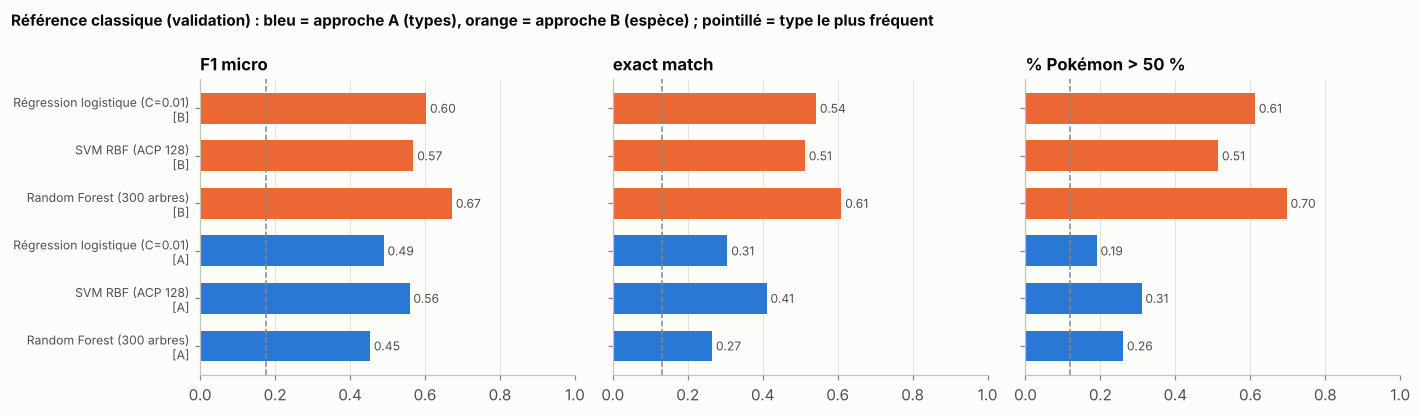

In [21]:
res = pd.DataFrame(resultats)
garder = res["modèle"].str.startswith("Référence") | ~res["modèle"].str.contains(r"C=0\.0(03|3)\)")   # on garde C=0.01
comp = res[garder].set_index(["approche", "modèle"])
cols = ["F1 micro", "F1 macro", "exact match", "≥ 1 type correct", "% Pokémon > 50 %", "% Pokémon > 70 %", "% Pokémon > 90 %"]
display(comp[cols + ["top-1", "top-5"]].round(3))

comp_plot = comp[~comp.index.get_level_values(1).str.startswith("Référence")]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
etiq = [f"{m}\n[{a[0]}]" for a, m in comp_plot.index]
for ax, met in zip(axes, ["F1 micro", "exact match", "% Pokémon > 50 %"]):
    cols_bar = [SERIES[0] if a.startswith("A") else SERIES[1] for a, _ in comp_plot.index]
    ax.barh(range(len(comp_plot)), comp_plot[met], color=cols_bar, height=0.65)
    ref = comp.loc[("A (types)", "Référence : type le plus fréquent"), met]
    ax.axvline(ref, color=MUTED, ls="--", lw=1)
    for i, v in enumerate(comp_plot[met]):
        ax.text(v + 0.01, i, f"{v:.2f}", va="center", fontsize=8, color=INK_2)
    ax.set_title(met)
    ax.set_xlim(0, 1)
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(range(len(comp_plot)), etiq, fontsize=8)
axes[0].invert_yaxis()
fig.suptitle("Référence classique (validation) : bleu = approche A (types), orange = approche B (espèce) ; "
             "pointillé = type le plus fréquent", x=0.01, ha="left", fontweight="bold", fontsize=10)
fig.tight_layout()
save_fig(fig, "n2_11_reference_classique")
plt.show()

### 2.6 Généralisation à des Pokémon jamais vus (5 plis groupés par espèce, approche A)

On reprend la meilleure régression logistique et la Random Forest de l'approche A. Chaque modèle est réentraîné 5 fois, à chaque fois **sans** les environ 28 espèces du pli évalué, qu'il n'a donc **jamais vues**. Sur les 14 715 images, train et validation confondus, les 5 plis permettent d'évaluer chaque Pokémon une fois.

In [22]:
gen = {}
for nom, fabrique in [("Référence : type le plus fréquent", None),
                      ("Régression logistique (C=0.01)", lambda: make_pipeline(StandardScaler(),
                           OneVsRestClassifier(LogisticRegression(C=0.01, max_iter=3000), n_jobs=-1))),
                      ("Random Forest (300 arbres)", lambda: RandomForestClassifier(n_estimators=300, n_jobs=-1,
                                                                                     random_state=RANDOM_STATE))]:
    scores, corr_all = [], np.zeros(len(splits), dtype=bool)
    for k in range(5):
        te_k = (splits["fold"] == k).to_numpy()
        if fabrique is None:
            P = np.tile(Ys[~te_k].mean(0), (te_k.sum(), 1))
        else:
            P = proba_multi(fabrique().fit(X[~te_k], Ys[~te_k]), X[te_k])
        D = decide_types(P)
        scores.append(multilabel_scores(Ys[te_k], D))
        corr_all[te_k] = (Ys[te_k] == D).all(1)
    _, cov = coverage(corr_all, sp)
    gen[nom] = {**{m: f"{np.mean([s[m] for s in scores]):.3f} ± {np.std([s[m] for s in scores]):.3f}"
                   for m in scores[0]}, **{m: f"{v:.3f}" for m, v in cov.items()}}
pd.DataFrame(gen).T

,F1 micro,F1 macro,Hamming loss,exact match,≥ 1 type correct,% Pokémon > 50 %,% Pokémon > 70 %,% Pokémon > 90 %
Référence : type le plus fréquent,0.152 ± 0.029,0.018 ± 0.003,0.122 ± 0.007,0.077 ± 0.045,0.186 ± 0.036,0.070,0.070,0.070
Régression logistique (C=0.01),0.356 ± 0.013,0.260 ± 0.021,0.099 ± 0.004,0.194 ± 0.027,0.431 ± 0.016,0.127,0.000,0.000
Random Forest (300 arbres),0.346 ± 0.019,0.159 ± 0.015,0.094 ± 0.007,0.197 ± 0.061,0.422 ± 0.011,0.183,0.120,0.063


**Lecture : ce que valent des caractéristiques choisies à la main**

**1. Pokémon connus (validation) : l'approche B l'emporte nettement.**
- **Reconnaître l'espèce marche déjà assez bien.** La Random Forest trouve la bonne espèce **une fois sur deux** (top-1 de 0,51, top-5 de 0,74). Le hasard ferait 0,7 %, et la référence « espèce la plus fréquente » 1,1 %. Couleur et silhouette suffisent donc souvent à distinguer un Pokémon.
- **À métriques égales sur les types, B bat A :**
  - la Random Forest en B obtient un exact match de 0,61, contre 0,41 pour le meilleur modèle A (le SVM) ;
  - un F1 micro de 0,67 contre 0,56 ;
  - et même pour « ≥ 1 type correct », 0,71 contre 0,61.
- **Explication :** l'espèce est une étiquette **concrète** et cohérente (toutes les images de Bulbizarre se ressemblent). Elle apporte **ses deux types d'un coup**. Les types, eux, sont des concepts **abstraits** qui regroupent des Pokémon très différents. Une Random Forest en A, qui prédit 17 sorties à la fois, s'y perd (F1 macro de 0,27).
- **Réglage :** la régression logistique varie peu avec $C$. En B, $C = 0{,}003$ est très légèrement meilleur (top-1 de 0,47 contre 0,45). On garde $C = 0{,}01$ dans les comparaisons, l'écart étant négligeable.

**2. Couverture : le point faible, et un piège de lecture.**
- **Le meilleur modèle (B, Random Forest)** dépasse 50 % d'exact match pour **70 % des Pokémon**, mais seulement 31 % des Pokémon au-delà de 70 %, et **2 %** au-delà de 90 %. La réussite est très inégale d'un Pokémon à l'autre.
- **Le piège :** la référence « toujours Eau » obtient **12 % de Pokémon au-dessus de 90 %**, plus que tous les modèles. C'est un **artefact**. Elle réussit à 100 % les 17 Pokémon de type Eau pur, et échoue à 0 % sur les 125 autres. **La couverture doit donc toujours se lire avec la réussite moyenne et avec une référence** : un modèle « paresseux » peut couvrir parfaitement quelques Pokémon et n'en servir aucun autre.

**3. Pokémon jamais vus (5 plis groupés) : les scores s'effondrent.**
- Le F1 micro tombe à **environ 0,35**, contre 0,15 pour la référence, et l'exact match à **environ 0,19** (référence : 0,08). Les modèles retrouvent surtout **un** type par la couleur : 43 % d'images avec au moins un type juste.
- **Couverture :** seuls 13 à 18 % des Pokémon inconnus dépassent 50 % d'exact match. Les types rares (2 à 5 espèces) ne sont presque jamais retrouvés (F1 macro ≤ 0,26).
- Cela confirme l'analyse de 1.4 : **généraliser le concept de type à partir de 142 espèces est difficile**.

**4. Pourquoi aller plus loin ?**
- Ces caractéristiques ignorent la **texture**, les **parties** (ailes, flammes, nageoires) et leur **agencement**. Un HOG de 64 × 64 « voit » une silhouette floue.
- Un réseau convolutif **apprend lui-même** des filtres hiérarchiques : bords, puis motifs, puis parties, puis objets. Un réseau **pré-entraîné sur ImageNet** apporte en plus des millions d'images d'expérience.
- **Niveau à battre (validation) :**
  - **approche B** : top-1 de 0,51 en espèce, exact match de 0,61 en types, 70 % des Pokémon au-dessus de 50 % ;
  - **approche A** : F1 micro de 0,56 ;
  - **Pokémon jamais vus** : F1 micro d'environ 0,35.

## 3. CNN entraîné de zéro (*from scratch*)

### 3.1 Principe

Un **réseau de neurones convolutif** (CNN) apprend **lui-même** ses caractéristiques, au lieu d'utiliser des caractéristiques conçues à la main comme le HOG ou l'histogramme de couleurs.

**La convolution.** Un filtre $3 \times 3$ glisse sur l'image et calcule en chaque position une somme pondérée des pixels voisins : $(I * W)(i, j) = \sum_{u, v} I(i + u, j + v)\, W(u, v)$. Les poids $W$ sont **appris** par descente de gradient. Les premiers filtres deviennent des détecteurs de bords et de couleurs. En empilant les couches, le **champ récepteur** grandit et les motifs se combinent : bords, puis textures, puis parties (œil, aile, flamme), puis objets.

**Architecture utilisée** (`src/train_images.py`, environ 0,7 million de paramètres) :
- 4 blocs `[Conv 3×3 → BatchNorm → ReLU] × 2 → MaxPool 2×2`, avec 24, 48, 96 puis 192 filtres ;
- `GlobalAveragePooling` (moyenne de chaque carte) → `Dropout(0,4)` → sortie : **17 sigmoïdes** (A) ou **softmax sur 142 espèces** (B) ;
- **BatchNorm** normalise les activations de chaque couche sur le batch, ce qui stabilise l'apprentissage. **Dropout** éteint aléatoirement 40 % des neurones, ce qui régularise.

**Entraînement** (images en **96 × 96** pour tenir le budget CPU : environ 2,5 minutes par époque) :
- **optimiseur AdamW** : descente de gradient adaptative, avec pénalité des poids ($10^{-4}$) ;
- **pas d'apprentissage** initial de $2 \cdot 10^{-3}$, divisé par 2 quand la validation stagne 3 époques ;
- **arrêt anticipé** (*early stopping*) : on arrête quand la loss de **validation** ne s'améliore plus pendant 6 époques, et on **revient aux poids de la meilleure époque** ;
- **data augmentation** sur le train uniquement, à chaque époque : symétrie horizontale, rotation de ± 22°, zoom de ± 15 %, translation de ± 8 %, luminosité, contraste, saturation, flou gaussien. Les zones vides sont complétées en blanc. **On ne modifie pas la teinte**, car la couleur est un indice essentiel du type ;
- **coûts pondérés contre le déséquilibre :**
  - **A** : entropie croisée binaire pondérée, où le poids des positifs du type $k$ vaut $w_k = \sqrt{n^-_k / n^+_k}$. Il va d'environ 2 pour Eau à environ 9 pour Acier. La racine carrée évite les poids extrêmes, qui gonflaient les probabilités au niveau 1 ;
  - **B** : poids par espèce $n / (S \cdot n_s)$.

Les entraînements sont lancés par `python -m src.train_images --model cnn_scratch --approach A` (ou `B`). Le notebook **relit** les résultats sauvegardés : historiques, prédictions sur la validation et modèles dans `models/candidates/`.

I0000 00:00:1793907719.199189   26827 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1793907720.706689   26827 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


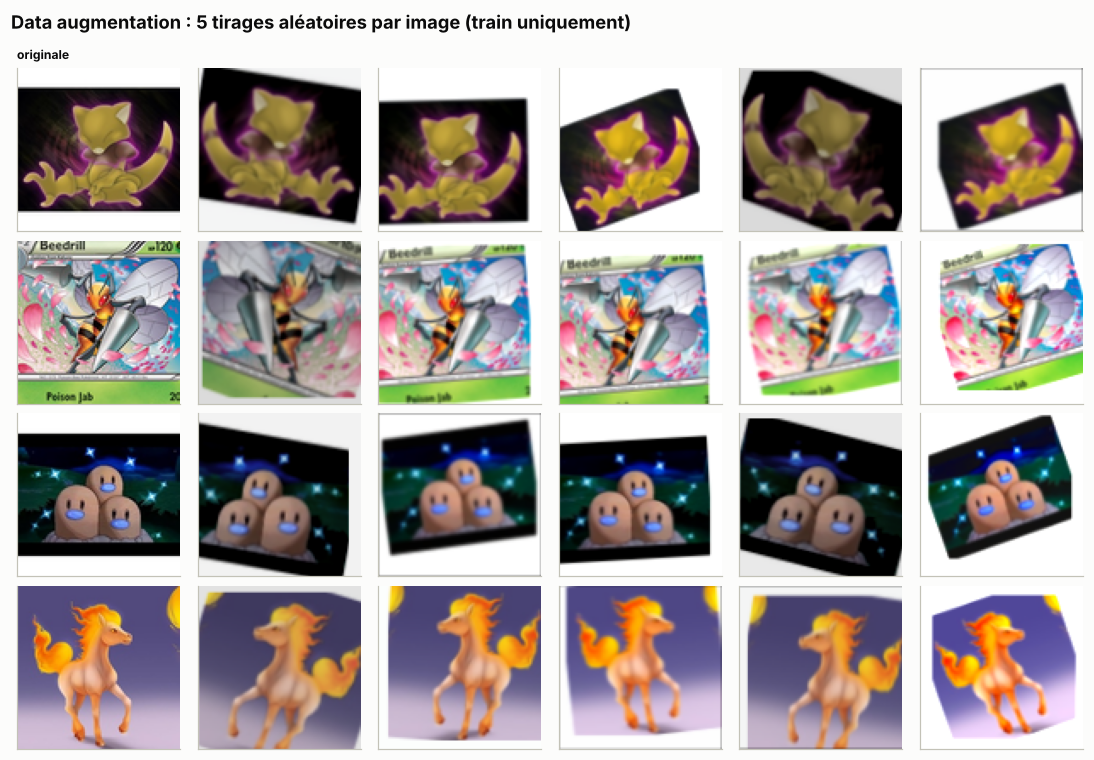

In [23]:
import json
from src.train_images import HISTORIES, PREDS, augmentation, load_arrays

def charge(nom):
    info = json.loads((HISTORIES / f"{nom}.json").read_text(encoding="utf-8"))
    return info, np.load(PREDS / f"{nom}_val.npy")

# Illustration de l'augmentation sur quelques images du train
X96 = load_arrays(96)
ex = X96[np.nonzero(tr)[0][[5, 400, 2000, 7000]]]
aug = augmentation()
fig, axes = plt.subplots(4, 6, figsize=(10, 7))
for i, img in enumerate(ex):
    axes[i, 0].imshow(img)
    axes[i, 0].set_title("originale" if i == 0 else "", fontsize=8)
    for j in range(1, 6):
        axes[i, j].imshow(np.clip(aug(img[None].astype("float32"), training=True)[0].numpy(), 0, 255).astype("uint8"))
for a in axes.flat:
    a.set_xticks([]); a.set_yticks([]); a.grid(False)
fig.suptitle("Data augmentation : 5 tirages aléatoires par image (train uniquement)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save_fig(fig, "n2_12_augmentation")
plt.show()

### 3.2 Courbes d'apprentissage

On compare l'erreur sur le **train** et sur la **validation**, époque par époque :
- si les deux baissent ensemble, le modèle **apprend** ;
- si la loss de validation **remonte** alors que celle du train continue de baisser, c'est du **surapprentissage** : le modèle mémorise les images d'entraînement au lieu de généraliser.

L'arrêt anticipé garde les poids de la meilleure époque de validation.

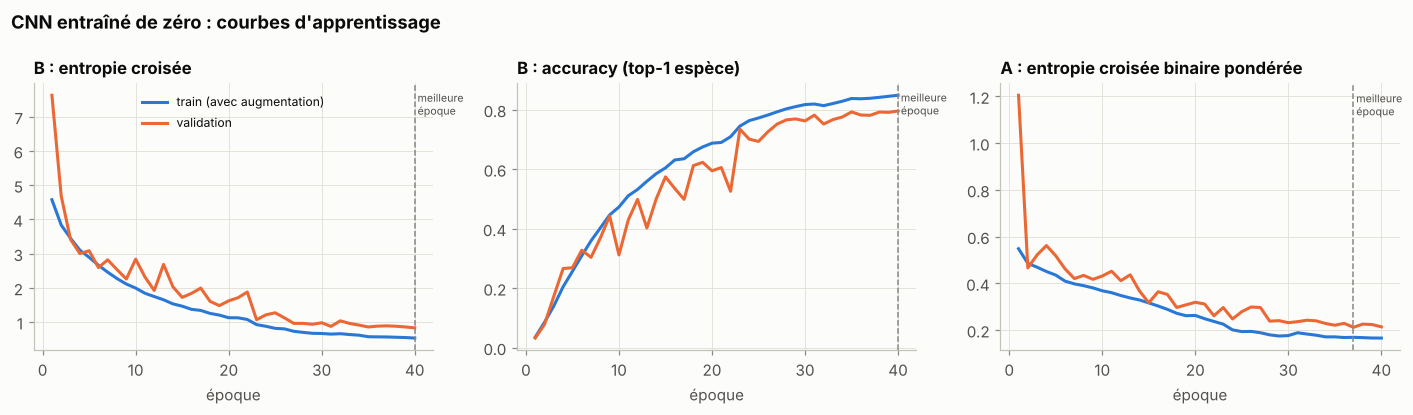

Approche A : Entraînement interrompu par des redémarrages de la session puis repris (BackupAndRestore) ; historique reconstruit à partir du journal. Les époques se recoupent au plus à une près.
Approche A : 40 époques, meilleure = 37, 87 min d'entraînement, 665,177 paramètres, 3.3 ms/image en inférence
Approche B : 40 époques, meilleure = 40, 92 min d'entraînement, 689,302 paramètres, 2.6 ms/image en inférence


In [24]:
infos = {a: charge(f"cnn_scratch_{a}") for a in ["A", "B"]}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, (a, met, titre) in zip(axes, [("B", "loss", "B : entropie croisée"), ("B", "acc", "B : accuracy (top-1 espèce)"),
                                      ("A", "loss", "A : entropie croisée binaire pondérée")]):
    h = infos[a][0]["history"]
    ep = np.arange(1, len(h[met]) + 1)
    ax.plot(ep, h[met], color=SERIES[0], label="train (avec augmentation)")
    ax.plot(ep, h[f"val_{met}"], color=SERIES[1], label="validation")
    ax.axvline(infos[a][0]["best_epoch"], color=MUTED, ls="--", lw=1)
    ax.text(infos[a][0]["best_epoch"] + 0.3, ax.get_ylim()[1] * 0.97, "meilleure\népoque", fontsize=7, color=INK_2, va="top")
    ax.set(title=titre, xlabel="époque")
axes[0].legend(fontsize=8)
fig.suptitle("CNN entraîné de zéro : courbes d'apprentissage", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save_fig(fig, "n2_13_courbes_cnn_scratch")
plt.show()
if "note" in infos["A"][0]:
    print("Approche A :", infos["A"][0]["note"])
for a in ["A", "B"]:
    i = infos[a][0]
    print(f"Approche {a} : {i['epochs_run']} époques, meilleure = {i['best_epoch']}, "
          f"{i['train_time_s'] / 60:.0f} min d'entraînement, {i['params']:,} paramètres, "
          f"{i['infer_ms_per_image']:.1f} ms/image en inférence")

### 3.3 Résultats sur la validation, comparés à la référence classique

In [25]:
info_B, P_B = infos["B"]
info_A, P_A = infos["A"]
resultats.append(eval_B(P_B, np.array(info_B["classes"]), "CNN de zéro (96 px)", info_B["train_time_s"]))
resultats.append(eval_A(P_A, "CNN de zéro (96 px)", info_A["train_time_s"]))
res = pd.DataFrame(resultats)
garder = res["modèle"].str.startswith("Référence") | ~res["modèle"].str.contains(r"C=0\.0(03|3)\)")
cols = ["top-1", "top-5", "F1 micro", "F1 macro", "Hamming loss", "exact match", "≥ 1 type correct",
        "% Pokémon > 50 %", "% Pokémon > 70 %", "% Pokémon > 90 %", "durée (s)"]
res[garder].set_index(["approche", "modèle"])[cols].round(3)

top-1  top-5  F1 micro  \
approche   modèle                                                         
A (types)  Référence : type le plus fréquent       NaN    NaN     0.177   
B (espèce) Référence : espèce la plus fréquente  0.011  0.043     0.177   
           Régression logistique (C=0.01)        0.452  0.676     0.603   
           SVM RBF (ACP 128)                     0.445  0.631     0.569   
           Random Forest (300 arbres)            0.510  0.737     0.672   
A (types)  Régression logistique (C=0.01)          NaN    NaN     0.490   
           SVM RBF (ACP 128)                       NaN    NaN     0.559   
           Random Forest (300 arbres)              NaN    NaN     0.453   
B (espèce) CNN de zéro (96 px)                   0.796  0.930     0.872   
A (types)  CNN de zéro (96 px)                     NaN    NaN     0.774   

                                                 F1 macro  Hamming loss  \
approche   modèle                                                         
A (types)  Référence : type le plus fréquent        0.021         0.119   
B (espèce) Référence : espèce la plus fréquente     0.021         0.119   
           Régression logistique (C=0.01)           0.582         0.068   
           SVM RBF (ACP 128)                        0.552         0.073   
           Random Forest (300 arbres)               0.642         0.056   
A (types)  Régression logistique (C=0.01)           0.458         0.079   
           SVM RBF (ACP 128)                        0.548         0.068   
           Random Forest (300 arbres)               0.271         0.079   
B (espèce) CNN de zéro (96 px)                      0.852         0.022   
A (types)  CNN de zéro (96 px)                      0.751         0.040   

                                                 exact match  \
approche   modèle                                              
A (types)  Référence : type le plus fréquent           0.131   
B (espèce) Référence : espèce la plus fréquente        0.131   
           Régression logistique (C=0.01)              0.542   
           SVM RBF (ACP 128)                           0.513   
           Random Forest (300 arbres)                  0.610   
A (types)  Régression logistique (C=0.01)              0.306   
           SVM RBF (ACP 128)                           0.411   
           Random Forest (300 arbres)                  0.265   
B (espèce) CNN de zéro (96 px)                         0.847   
A (types)  CNN de zéro (96 px)                         0.628   

                                                 ≥ 1 type correct  \
approche   modèle                                                   
A (types)  Référence : type le plus fréquent                0.216   
B (espèce) Référence : espèce la plus fréquente             0.216   
           Régression logistique (C=0.01)                   0.636   
           SVM RBF (ACP 128)                                0.597   
           Random Forest (300 arbres)                       0.707   
A (types)  Régression logistique (C=0.01)                   0.567   
           SVM RBF (ACP 128)                                0.607   
           Random Forest (300 arbres)                       0.553   
B (espèce) CNN de zéro (96 px)                              0.888   
A (types)  CNN de zéro (96 px)                              0.844   

                                                 % Pokémon > 50 %  \
approche   modèle                                                   
A (types)  Référence : type le plus fréquent                0.120   
B (espèce) Référence : espèce la plus fréquente             0.120   
           Régression logistique (C=0.01)                   0.613   
           SVM RBF (ACP 128)                                0.514   
           Random Forest (300 arbres)                       0.697   
A (types)  Régression logistique (C=0.01)                   0.190   
           SVM RBF (ACP 128)                                0.310   
           Random Forest (30

**Lecture**

**1. Courbes d'apprentissage : pas de surapprentissage marqué, et un modèle B qui progressait encore.**
- **Pour B**, les courbes du train et de la validation baissent ensemble pendant 40 époques. L'écart final reste modéré : 85 % d'accuracy en train (avec augmentation) contre 80 % en validation.
- **La meilleure époque de B est la dernière.** L'arrêt anticipé ne s'est pas déclenché : le modèle aurait encore gagné un peu avec plus d'époques. C'est une limite du budget CPU, d'environ 1 h 30 par modèle.
- **La data augmentation et le dropout jouent leur rôle de régularisation.** Sans eux, un réseau de 0,7 million de paramètres entraîné sur 10 300 images mémoriserait vite le train.
- **Pour A**, l'entraînement a été **interrompu plusieurs fois** par des redémarrages de la session, puis **repris** grâce à la sauvegarde à chaque époque. L'historique complet a été reconstruit à partir du journal. La meilleure époque est la 37ᵉ.

**2. Le CNN de zéro écrase la référence classique.**
- **Approche B :**
  - **top-1 de 0,80** en espèce, contre 0,51 pour la meilleure référence, et un top-5 de 0,93 ;
  - **exact match des types de 0,85**, contre 0,61.
  
  L'exact match des types dépasse le top-1 de l'espèce. Quand le réseau se trompe d'espèce, il choisit souvent une espèce **de même type**, typiquement un Pokémon de la même lignée d'évolution (Ponyta contre Galopa, Magnéti contre Magnéton).
- **Approche A :** F1 micro de 0,77 et exact match de 0,63, contre 0,56 et 0,41 pour le meilleur modèle classique.
- **Le réseau apprend des caractéristiques bien plus riches que l'histogramme de couleurs et le HOG** : textures, parties du corps et leur agencement.

**3. La couverture fait un bond.**
- **Avec B, 99 % des Pokémon** dépassent 50 % d'exact match sur les types, **86 % dépassent 70 %** et **42 % dépassent 90 %**. La référence en était à 70 %, 31 % et 2 %.
- **Il reste des Pokémon difficiles.** Les espèces les moins bien reconnues sont reconnues dans seulement 40 à 55 % des cas : Ossatueur, Galopa, Magnéton, Dracolosse, Akwakwak, Smogo, Rhinocorne, Arcanin. Ce sont souvent des Pokémon **proches d'un autre** : leur pré-évolution ou leur évolution leur ressemble beaucoup. Cette analyse sera approfondie en partie 5, avec Grad-CAM.

**4. A ou B ?**
- **B reste nettement devant A** pour les Pokémon connus : 0,85 contre 0,63 d'exact match, 99 % contre 64 % des Pokémon au-dessus de 50 %. La conclusion de la référence classique se confirme.
- A garde l'avantage de principe de pouvoir généraliser à des Pokémon inconnus. Ce sera testé sur le meilleur modèle, en partie 4.

**5. Coût.**
- **Entraînement :** environ 1 h 30 par approche sur CPU.
- **Inférence :** environ 3 ms par image.
- **Taille :** environ 8 Mo par modèle.
- C'est léger, mais le réseau est **limité à 96 × 96 pixels** et n'a vu que nos 10 300 images. Le **transfer learning** (partie 4) va réutiliser un réseau pré-entraîné sur les 1,3 million d'images d'ImageNet. On s'attend à mieux, avec beaucoup moins d'époques.

## 4. Transfer learning : réutiliser un réseau pré-entraîné sur ImageNet

### 4.1 Principe

Un réseau entraîné sur **ImageNet** (1,3 million de photos, 1 000 catégories : animaux, objets, scènes) a déjà appris des filtres très généraux. Ses premières couches détectent des bords, des couleurs et des textures, ses couches profondes des formes, des parties et des objets. Ces caractéristiques sont **réutilisables** pour d'autres images, même des dessins de Pokémon : c'est le **transfer learning**.

**Deux façons de l'utiliser :**
1. **Réseau gelé** (*feature extraction*). On retire la dernière couche d'ImageNet, et on fait passer chaque image dans le réseau **une seule fois** pour obtenir un **vecteur de caractéristiques** (de 576 à 2 048 valeurs selon le réseau). On entraîne ensuite **une seule couche** `Dropout → Dense` (sigmoïde pour A, softmax pour B) sur ces vecteurs. C'est **très rapide** : quelques dizaines de secondes, et les caractéristiques sont calculées une fois pour toutes.
2. **Fine-tuning.** En partant de la tête entraînée en 1, on **dégèle les dernières couches** du réseau et on réentraîne l'ensemble, avec un **petit pas d'apprentissage** ($10^{-4}$, 20 fois plus petit qu'en partie 3) et la data augmentation. Les couches profondes s'adaptent alors aux Pokémon. Deux précautions :
   - le petit pas évite de **détruire** les caractéristiques apprises sur ImageNet. C'est l'« oubli catastrophique », dû à des gradients trop grands au début, quand la tête est encore imparfaite ;
   - les couches **BatchNorm restent gelées**, sur les statistiques d'ImageNet. Avec des batchs de 32 images, leurs moyennes et variances seraient trop bruitées.

**Les réseaux comparés** (tous en entrée 224 × 224) :

| Réseau | Idée | Taille |
|---|---|---|
| **MobileNetV3-Small / Large** | convolutions **séparables en profondeur** (*depthwise* puis *pointwise*), bien moins coûteuses que des convolutions pleines. Architecture trouvée par recherche automatique, pour mobiles | 0,9 M / 3,0 M paramètres |
| **EfficientNetB0** | *compound scaling* : profondeur, largeur et résolution augmentées de façon équilibrée. Blocs MBConv avec *squeeze-and-excitation* | 4,0 M |
| **ResNet50** | **connexions résiduelles** $y = F(x) + x$ : le gradient traverse 50 couches sans s'évanouir | 23,5 M |

### 4.2 Phase 1 : réseaux gelés + une couche entraînée

Les vecteurs de caractéristiques des 14 715 images sont calculés par `src.train_images.extract_embeddings`, sans augmentation, et mis en cache. On entraîne ensuite la tête sur le train, avec arrêt anticipé sur la validation. La fonction de coût est pondérée comme en partie 3 : $w_k = \sqrt{n^-_k / n^+_k}$ pour A, poids par espèce pour B.

In [26]:
from src.train_images import BACKBONES, extract_embeddings, train_head, targets, CACHE_DIR as TCACHE
import keras
EMB = {b: extract_embeddings(b) for b in BACKBONES}             # cache : data/cache/emb_<réseau>.npy
ms_extract = {b: float((TCACHE / f"emb_{b}.time").read_text()) for b in BACKBONES}
taille_params = {"mobilenetv3_small": 0.94, "mobilenetv3_large": 3.0, "efficientnet_b0": 4.05, "resnet50": 23.6}
NOMS = {"mobilenetv3_small": "MobileNetV3-Small", "mobilenetv3_large": "MobileNetV3-Large",
        "efficientnet_b0": "EfficientNetB0", "resnet50": "ResNet50"}

tetes = {}
for b, E in EMB.items():
    for a in ["B", "A"]:
        y_a, cl_a = targets(splits, a)
        t0 = time.time()
        head, hist = train_head(E, y_a, a, tr, va)
        P = head.predict(E[va], verbose=0)
        d = time.time() - t0
        nom = f"{NOMS[b]} gelé"
        resultats.append(eval_B(P, cl_a, nom, d) if a == "B" else eval_A(P, nom, d))
        tetes[(b, a)] = head
gel = pd.DataFrame(resultats)
gel = gel[gel["modèle"].str.endswith("gelé")].set_index(["approche", "modèle"])
gel["inférence (ms/image)"] = [ms_extract[k] for k in [b for b in BACKBONES for _ in "BA"]]
gel["paramètres (M)"] = [taille_params[k] for k in [b for b in BACKBONES for _ in "BA"]]
gel[["top-1", "top-5", "F1 micro", "F1 macro", "exact match", "% Pokémon > 50 %", "% Pokémon > 70 %",
     "% Pokémon > 90 %", "durée (s)", "inférence (ms/image)", "paramètres (M)"]].round(3)

,,top-1,top-5,F1 micro,F1 macro,exact match,% Pokémon > 50 %,% Pokémon > 70 %,% Pokémon > 90 %,durée (s),inférence (ms/image),paramètres (M)
approche,modèle,,,,,,,,,,,
B (espèce),MobileNetV3-Small gelé,0.810,0.942,0.882,0.878,0.860,1.000,0.908,0.387,35.065,4.51,0.94
A (types),MobileNetV3-Small gelé,NaN,NaN,0.701,0.714,0.497,0.472,0.141,0.014,25.113,4.51,0.94
B (espèce),MobileNetV3-Large gelé,0.839,0.947,0.905,0.904,0.885,1.000,0.951,0.500,26.172,10.64,3.00
A (types),MobileNetV3-Large gelé,NaN,NaN,0.757,0.776,0.578,0.634,0.289,0.007,23.645,10.64,3.00
B (espèce),EfficientNetB0 gelé,0.858,0.955,0.911,0.913,0.895,1.000,0.958,0.563,42.730,15.90,4.05
A (types),EfficientNetB0 gelé,NaN,NaN,0.783,0.797,0.613,0.683,0.359,0.021,23.896,15.90,4.05
B (espèce),ResNet50 gelé,0.855,0.965,0.918,0.918,0.898,1.000,0.965,0.535,25.348,41.43,23.60
A (types),ResNet50 gelé,NaN,NaN,0.794,0.810,0.621,0.725,0.331,0.042,20.885,41.43,23.60


**Lecture : un réseau gelé bat déjà le CNN de zéro, en une minute d'entraînement**

- **Approche B :** les quatre réseaux pré-entraînés gelés battent le CNN de zéro, qui plafonnait à un top-1 de 0,80.
  - De 0,81 (MobileNetV3-Small) à **environ 0,86** (EfficientNetB0 et ResNet50) en espèce.
  - Exact match des types jusqu'à environ 0,90, et **100 % des Pokémon au-dessus de 50 %**.
  - Tout cela avec **une seule couche entraînée**, en moins d'une minute sur CPU, contre 1 h 30 pour le CNN de zéro. Les caractéristiques apprises sur ImageNet (formes, textures, parties) décrivent très bien des Pokémon, alors même qu'il s'agit souvent de dessins.
- **Approche A :** les réseaux gelés font environ jeu égal avec le CNN de zéro (F1 micro de 0,70 à 0,79, exact match de 0,50 à 0,62). Prédire les types reste plus difficile que reconnaître l'espèce, pour la même raison qu'en parties 2 et 3.
- **Plus le réseau est grand, meilleures sont ses caractéristiques**, mais avec des rendements décroissants :
  - de MobileNetV3-Small (0,9 M paramètres) à MobileNetV3-Large (3 M), on gagne environ 3 points de top-1 ;
  - d'EfficientNetB0 (4 M) à ResNet50 (23,5 M), on ne gagne plus rien, pour un réseau **6 fois plus gros et environ 3 fois plus lent** (environ 40 ms par image contre 16 sur ces CPU).
- **Choix pour le fine-tuning : EfficientNetB0.** C'est le meilleur compromis entre précision, taille et vitesse. Il est léger (environ 16 Mo, environ 16 ms par image), ce qui est compatible avec l'appli sur CPU et la caméra du niveau 3.

### 4.3 Généralisation à des Pokémon jamais vus (approche A, 5 plis groupés par espèce)

Avec des caractéristiques gelées, le test sur des Pokémon **jamais vus** (protocole de 1.4) ne coûte que quelques minutes : 5 têtes à entraîner par réseau. On le fait pour les trois meilleurs réseaux et on compare avec la référence classique (partie 2.6).

In [27]:
y_A, _ = targets(splits, "A")
gen_tl = {}
for b in ["mobilenetv3_large", "efficientnet_b0", "resnet50"]:
    E = EMB[b]
    scores, corr_all = [], np.zeros(len(splits), dtype=bool)
    for k in range(5):
        te_k = (splits["fold"] == k).to_numpy()
        # validation interne pour l'arrêt anticipé : on prend la partie « val » des plis d'entraînement
        tr_k, va_k = (~te_k) & ~va, (~te_k) & va
        head, _ = train_head(E, y_A, "A", tr_k, va_k)
        D = decide_types(head.predict(E[te_k], verbose=0))
        scores.append(multilabel_scores(Ys[te_k], D))
        corr_all[te_k] = (Ys[te_k] == D).all(1)
    _, cov = coverage(corr_all, sp)
    gen_tl[f"{NOMS[b]} gelé"] = {**{m: f"{np.mean([s[m] for s in scores]):.3f} ± {np.std([s[m] for s in scores]):.3f}"
                                   for m in scores[0]}, **{m: f"{v:.3f}" for m, v in cov.items()}}
pd.concat([pd.DataFrame(gen).T, pd.DataFrame(gen_tl).T])

,F1 micro,F1 macro,Hamming loss,exact match,≥ 1 type correct,% Pokémon > 50 %,% Pokémon > 70 %,% Pokémon > 90 %
Référence : type le plus fréquent,0.152 ± 0.029,0.018 ± 0.003,0.122 ± 0.007,0.077 ± 0.045,0.186 ± 0.036,0.070,0.070,0.070
Régression logistique (C=0.01),0.356 ± 0.013,0.260 ± 0.021,0.099 ± 0.004,0.194 ± 0.027,0.431 ± 0.016,0.127,0.000,0.000
Random Forest (300 arbres),0.346 ± 0.019,0.159 ± 0.015,0.094 ± 0.007,0.197 ± 0.061,0.422 ± 0.011,0.183,0.120,0.063
MobileNetV3-Large gelé,0.478 ± 0.020,0.388 ± 0.047,0.087 ± 0.004,0.268 ± 0.019,0.574 ± 0.027,0.176,0.063,0.000
EfficientNetB0 gelé,0.489 ± 0.026,0.404 ± 0.047,0.085 ± 0.004,0.274 ± 0.023,0.594 ± 0.036,0.190,0.049,0.000
ResNet50 gelé,0.504 ± 0.026,0.415 ± 0.046,0.082 ± 0.005,0.290 ± 0.025,0.606 ± 0.033,0.225,0.077,0.000


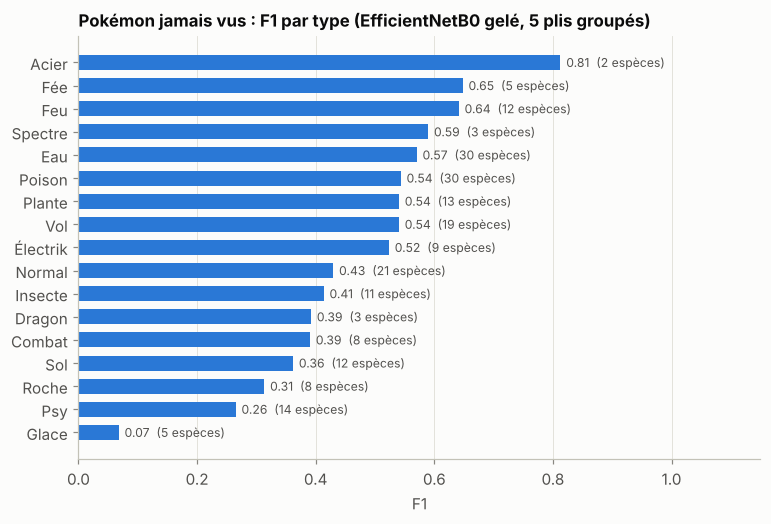

Corrélation de Spearman entre le nombre d'espèces d'un type et son F1 : ρ = -0.04 (p = 0.877)


In [28]:
# Quels types se généralisent ? F1 par type, Pokémon jamais vus, réseau gelé le plus performant
from sklearn.metrics import f1_score
b_best = "efficientnet_b0"
D_all = np.zeros_like(Ys)
for k in range(5):
    te_k = (splits["fold"] == k).to_numpy()
    head, _ = train_head(EMB[b_best], y_A, "A", (~te_k) & ~va, (~te_k) & va)
    D_all[te_k] = decide_types(head.predict(EMB[b_best][te_k], verbose=0))
f1_type = pd.Series(f1_score(Ys, D_all, average=None, zero_division=0), index=[TYPE_FR[t] for t in TYPES_IMAGES])
nb_esp = pd.Series({TYPE_FR[t]: splits.loc[Ys[:, j] == 1, "pokedex_number"].nunique() for j, t in enumerate(TYPES_IMAGES)})
o = f1_type.sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(o.index, o.values, color=SERIES[0], height=0.65)
for i, (t, v) in enumerate(o.items()):
    ax.text(v + 0.01, i, f"{v:.2f}  ({nb_esp[t]} espèces)", va="center", fontsize=8, color=INK_2)
ax.set(title=f"Pokémon jamais vus : F1 par type ({NOMS[b_best]} gelé, 5 plis groupés)", xlabel="F1", xlim=(0, 1.15))
ax.grid(axis="y", visible=False)
save_fig(fig, "n2_14_generalisation_par_type")
plt.show()
from scipy.stats import spearmanr
rho_g, p_g = spearmanr(nb_esp[o.index], o.values)
print(f"Corrélation de Spearman entre le nombre d'espèces d'un type et son F1 : ρ = {rho_g:.2f} (p = {p_g:.3f})")

### 4.4 Phase 2 : fine-tuning

On affine **EfficientNetB0**, pour les deux approches. On dégèle les 40 dernières couches (environ le dernier tiers du réseau), avec un pas de $10^{-4}$, la data augmentation, et un arrêt anticipé après 3 époques sans progrès (12 époques au maximum).

Commande : `python -m src.train_images --finetune efficientnet_b0 --approach B` (ou `A`). Le notebook relit les historiques et les prédictions sauvegardés.

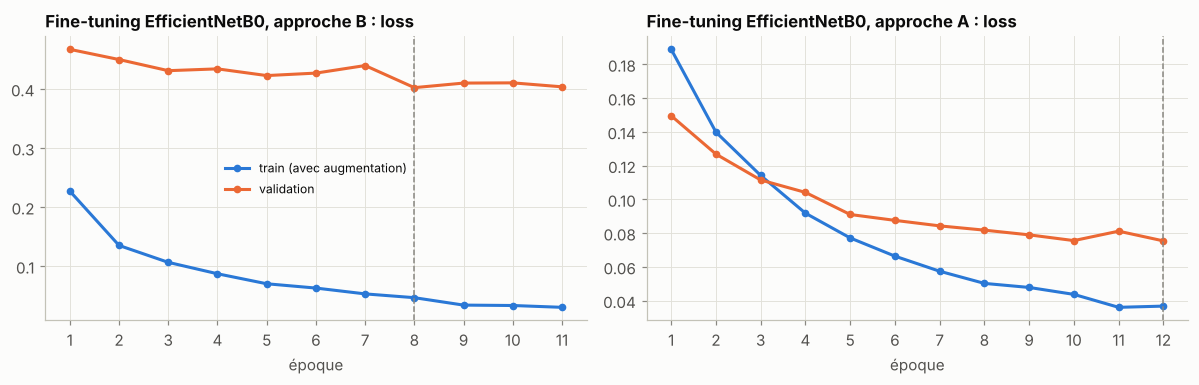

Approche B : 11 époques (meilleure 8), 48 min, 2.22 M paramètres entraînables sur 4.23 M, 13.2 ms/image, 37 Mo
Approche A : 12 époques (meilleure 12), 48 min, 2.06 M paramètres entraînables sur 4.07 M, 18.7 ms/image, 34 Mo


In [29]:
FT = "efficientnet_b0"
ft = {a: charge(f"{FT}_ft_{a}") for a in ["B", "A"]}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, a in zip(axes, ["B", "A"]):
    h = ft[a][0]["history"]
    ep = np.arange(1, len(h["loss"]) + 1)
    ax.plot(ep, h["loss"], color=SERIES[0], marker="o", ms=4, label="train (avec augmentation)")
    ax.plot(ep, h["val_loss"], color=SERIES[1], marker="o", ms=4, label="validation")
    ax.axvline(ft[a][0]["best_epoch"], color=MUTED, ls="--", lw=1)
    ax.set(title=f"Fine-tuning {NOMS[FT]}, approche {a} : loss", xlabel="époque")
    ax.set_xticks(ep)
axes[0].legend(fontsize=8)
fig.tight_layout()
save_fig(fig, "n2_15_courbes_finetuning")
plt.show()

for a in ["B", "A"]:
    info, P = ft[a]
    nom = f"{NOMS[FT]} fine-tuné"
    resultats.append(eval_B(P, np.array(info["classes"]), nom, info["train_time_s"]) if a == "B"
                     else eval_A(P, nom, info["train_time_s"]))
    print(f"Approche {a} : {info['epochs_run']} époques (meilleure {info['best_epoch']}), "
          f"{info['train_time_s'] / 60:.0f} min, {info['trainable_params'] / 1e6:.2f} M paramètres entraînables "
          f"sur {info['params'] / 1e6:.2f} M, {info['infer_ms_per_image']:.1f} ms/image, {info['size_mb']:.0f} Mo")

### 4.5 Tableau comparatif de tous les modèles (validation, Pokémon connus)

top-1  top-5  F1 micro  \
approche   modèle                                                         
A (types)  Référence : type le plus fréquent       NaN    NaN     0.177   
B (espèce) Référence : espèce la plus fréquente  0.011  0.043     0.177   
           Régression logistique (C=0.01)        0.452  0.676     0.603   
           SVM RBF (ACP 128)                     0.445  0.631     0.569   
           Random Forest (300 arbres)            0.510  0.737     0.672   
A (types)  Régression logistique (C=0.01)          NaN    NaN     0.490   
           SVM RBF (ACP 128)                       NaN    NaN     0.559   
           Random Forest (300 arbres)              NaN    NaN     0.453   
B (espèce) CNN de zéro (96 px)                   0.796  0.930     0.872   
A (types)  CNN de zéro (96 px)                     NaN    NaN     0.774   
B (espèce) MobileNetV3-Small gelé                0.810  0.942     0.882   
A (types)  MobileNetV3-Small gelé                  NaN    NaN     0.701   
B (espèce) MobileNetV3-Large gelé                0.839  0.947     0.905   
A (types)  MobileNetV3-Large gelé                  NaN    NaN     0.757   
B (espèce) EfficientNetB0 gelé                   0.858  0.955     0.911   
A (types)  EfficientNetB0 gelé                     NaN    NaN     0.783   
B (espèce) ResNet50 gelé                         0.855  0.965     0.918   
A (types)  ResNet50 gelé                           NaN    NaN     0.794   
B (espèce) EfficientNetB0 fine-tuné              0.908  0.981     0.951   
A (types)  EfficientNetB0 fine-tuné                NaN    NaN     0.933   

                                                 F1 macro  Hamming loss  \
approche   modèle                                                         
A (types)  Référence : type le plus fréquent        0.021         0.119   
B (espèce) Référence : espèce la plus fréquente     0.021         0.119   
           Régression logistique (C=0.01)           0.582         0.068   
           SVM RBF (ACP 128)                        0.552         0.073   
           Random Forest (300 arbres)               0.642         0.056   
A (types)  Régression logistique (C=0.01)           0.458         0.079   
           SVM RBF (ACP 128)                        0.548         0.068   
           Random Forest (300 arbres)               0.271         0.079   
B (espèce) CNN de zéro (96 px)                      0.852         0.022   
A (types)  CNN de zéro (96 px)                      0.751         0.040   
B (espèce) MobileNetV3-Small gelé                   0.878         0.020   
A (types)  MobileNetV3-Small gelé                   0.714         0.051   
B (espèce) MobileNetV3-Large gelé                   0.904         0.016   
A (types)  MobileNetV3-Large gelé                   0.776         0.041   
B (espèce) EfficientNetB0 gelé                      0.913         0.015   
A (types)  EfficientNetB0 gelé                      0.797         0.038   
B (espèce) ResNet50 gelé                            0.918         0.014   
A (types)  ResNet50 gelé                            0.810         0.035   
B (espèce) EfficientNetB0 fine-tuné                 0.950         0.008   
A (types)  EfficientNetB0 fine-tuné                 0.934         0.011   

                                                 exact match  \
approche   modèle                                              
A (types)  Référence : type le plus fréquent           0.131   
B (espèce) Référence : espèce la plus fréquente        0.131   
           Régression logistique (C=0.01)              0.542   
           SVM RBF (ACP 128)                           0.513   
           Random Forest (300 arbres)                  0.610   
A (types)  Régression logistique (C=0.01)              0.306   
           SVM RBF (ACP 128)                           0.411   
           Random Forest (300 arbres)                  0.265   
B (espèce) CNN de zéro (96 px)                         0.847   
A (types)  CNN de zéro (96 px)             

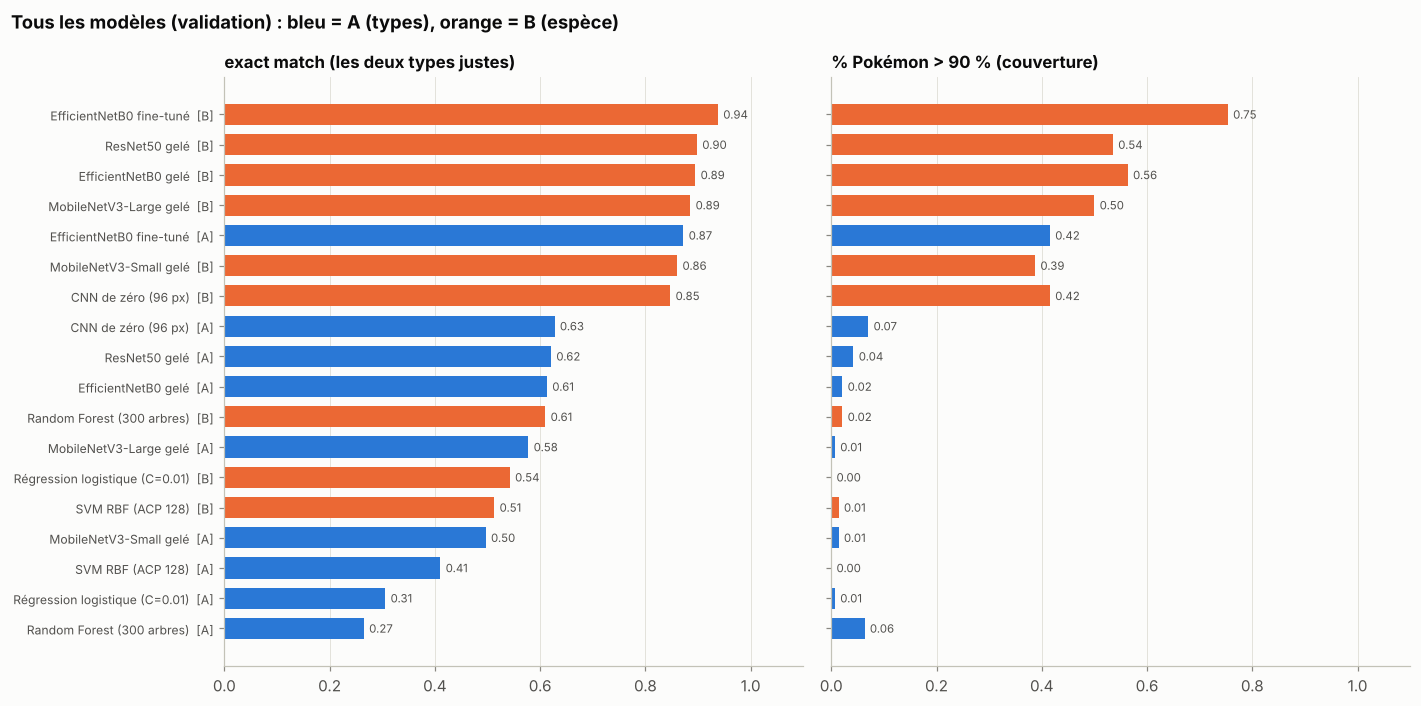

In [30]:
res = pd.DataFrame(resultats)
res = res[res["modèle"].str.startswith("Référence") | ~res["modèle"].str.contains(r"C=0\.0(03|3)\)")]
tab = res.set_index(["approche", "modèle"])[["top-1", "top-5", "F1 micro", "F1 macro", "Hamming loss", "exact match",
                                             "≥ 1 type correct", "% Pokémon > 50 %", "% Pokémon > 70 %",
                                             "% Pokémon > 90 %", "durée (s)"]]
tab.to_csv(ROOT_DIR / "reports" / "tables" / "recap_images_validation.csv")
display(tab.round(3))

plot = res[~res["modèle"].str.startswith("Référence")].copy()
plot["étiquette"] = plot["modèle"] + "  [" + plot["approche"].str[0] + "]"
plot = plot.sort_values("exact match")
fig, axes = plt.subplots(1, 2, figsize=(13, 6.5), sharey=True)
for ax, met in zip(axes, ["exact match", "% Pokémon > 90 %"]):
    ax.barh(plot["étiquette"], plot[met], color=[SERIES[0] if a.startswith("A") else SERIES[1] for a in plot["approche"]],
            height=0.7)
    for i, v in enumerate(plot[met]):
        ax.text(v + 0.01, i, f"{v:.2f}", va="center", fontsize=7.5, color=INK_2)
    ax.set(title=met + (" (couverture)" if "%" in met else " (les deux types justes)"), xlim=(0, 1.1))
    ax.grid(axis="y", visible=False)
axes[0].tick_params(axis="y", labelsize=8)
fig.suptitle("Tous les modèles (validation) : bleu = A (types), orange = B (espèce)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save_fig(fig, "n2_16_comparaison_tous_modeles")
plt.show()

**Lecture**

**1. Pokémon jamais vus (4.3) : le transfer learning généralise mieux, mais le problème reste difficile.**
- **Avec un réseau gelé, l'exact match passe de 0,19 à 0,27–0,29, et le F1 micro de 0,36 à environ 0,50.** C'est la référence classique contre les réseaux gelés, sur des Pokémon jamais vus. ResNet50 est le meilleur sur ce protocole, de peu. Au moins un type est juste pour 60 % des images.
- **La couverture reste faible :** seuls environ 20 % des Pokémon inconnus dépassent 50 % d'exact match. Deviner les **deux** types d'un Pokémon jamais vu reste rare.
- **Ce qui se généralise, ce n'est pas le nombre d'exemples, c'est la cohérence visuelle du type.** La corrélation entre le nombre d'espèces d'un type et son F1 est nulle (ρ ≈ −0,04).
  - **Acier**, avec seulement 2 espèces, se généralise **le mieux** (F1 de 0,81) : l'aspect métallique et gris de Magnéti suffit à reconnaître Magnéton.
  - **Fée** (rose, rond), **Feu** (flammes, orange) et **Spectre** (violet, fantomatique) ont un **indice visuel net**.
  - **Glace** (0,07), **Psy** (0,26) et **Roche** (0,31) réunissent des Pokémon **visuellement très différents**. Lokhlass, Lippoutou, Crustabri et Artikodin sont tous Glace, mais ne se ressemblent pas. Le type est alors un concept **narratif** plus que visuel.
- Ce test n'a été fait qu'avec des réseaux **gelés** : 5 fine-tunings de 48 minutes dépassaient le budget CPU. Le fine-tuning améliorerait sans doute aussi ces scores, ce qui est une piste pour le rapport.

**2. Fine-tuning (4.4) : un nouveau bond sur les Pokémon connus.**
- **Approche B (EfficientNetB0 affiné) :**
  - **top-1 de 0,91** et top-5 de 0,98 en espèce, contre 0,86 pour le réseau gelé et 0,80 pour le CNN de zéro ;
  - **exact match des types de 0,94** ;
  - **couverture : 100 % des Pokémon au-dessus de 50 %, 99 % au-dessus de 70 %, 75 % au-dessus de 90 %**.
- **Approche A (EfficientNetB0 affiné) :** F1 micro de 0,93 et exact match de 0,87, contre 0,78 et 0,61 pour le réseau gelé. **C'est l'approche qui profite le plus du fine-tuning.** Les couches profondes s'adaptent aux indices de type (matières, éléments), que les caractéristiques d'ImageNet ne captaient pas directement.
- **Courbes d'apprentissage :**
  - **en B**, le train atteint 99 % alors que la validation plafonne à environ 90 %, et la loss de validation remonte après quelques époques. C'est un **début de surapprentissage**, que l'arrêt anticipé contrôle en gardant la meilleure époque (la 8ᵉ) ;
  - **en A**, la validation progressait encore à la 12ᵉ époque (le maximum autorisé).
- **Les espèces les moins bien reconnues** le sont à 56–74 % : Roucoups, Nidoking, Ramoloss, Abra, Otaria, Galopa, Colossinge, Kadabra, Smogo, Têtarte. Ce sont presque toujours des Pokémon **d'une lignée d'évolution** qui ressemblent à leurs voisins (Roucool, Roucoups et Roucarnage ; Abra, Kadabra et Alakazam). Analyse détaillée en partie 5.

**3. Synthèse de la comparaison (4.5).**
- **Classement de tous les modèles :** référence classique < CNN de zéro < réseau gelé < **réseau affiné**, sur toutes les métriques et pour les deux approches.
- **Le transfer learning gagne à la fois en précision et en coût :** 48 minutes de fine-tuning contre 1 h 30 pour le CNN de zéro, bien moins bon.
- **Sur les Pokémon connus**, B affiné reste devant A affiné en exact match (0,94 contre 0,87) et en couverture au-delà de 90 % (75 % contre 42 %).
- **Mais A a deux atouts :**
  - il peut proposer des types pour un **Pokémon inconnu** (4.3) ;
  - il obtient « au moins un type correct » un peu plus souvent (0,96 contre 0,955).
- **Le choix final** (partie 6) se fera sur le jeu de test, en tenant compte de la couverture et de l'usage dans l'appli. Pour la caméra, l'approche B donne en plus le **nom** du Pokémon.

## 5. Évaluation finale sur le jeu de test, couverture et Grad-CAM

On évalue les **deux meilleurs modèles**, EfficientNetB0 fine-tuné en approche A et en approche B, **une seule fois** sur les 2 208 images du jeu de test, qui n'ont servi à **aucun choix**. Les seuils de décision de l'approche A sont réglés **sur la validation** avant de regarder le test.

### 5.1 Seuils de décision par type (approche A)

Au lieu du seuil de 0,5 pour tous les types, on choisit pour chaque type $k$ le seuil $t_k$ qui **maximise son F1 sur la validation**, sur une grille de 0,05 à 0,95. On garde la règle : au moins 1 type et au plus 2.

In [31]:
import keras
from sklearn.metrics import f1_score, precision_score, recall_score
from src.train_images import CANDIDATES, PREDS, load_arrays, make_dataset, grad_cam

te = (splits["split"] == "test").to_numpy()
Yte = Ys[te]
X224 = load_arrays(224)
modeles_finaux = {a: keras.saving.load_model(CANDIDATES / f"efficientnet_b0_ft_{a}.keras") for a in ["A", "B"]}
y_B, cl_B = targets(splits, "B")
P_test = {}
for a in ["A", "B"]:
    y_a, _ = targets(splits, a)
    P_test[a] = modeles_finaux[a].predict(make_dataset(X224[te], y_a[te], 64, False), verbose=0)
    np.save(PREDS / f"efficientnet_b0_ft_{a}_test.npy", P_test[a])

P_A_val = np.load(PREDS / "efficientnet_b0_ft_A_val.npy")
grille = np.arange(0.05, 0.96, 0.05)
seuils = np.array([grille[np.argmax([f1_score(Yva[:, k], P_A_val[:, k] >= t, zero_division=0) for t in grille])]
                   for k in range(K)])
np.save(ROOT_DIR / "models" / "seuils_types.npy", seuils)
pd.DataFrame({"seuil": seuils,
              "F1 val (seuil 0,5)": [f1_score(Yva[:, k], P_A_val[:, k] >= 0.5, zero_division=0) for k in range(K)],
              "F1 val (seuil réglé)": [f1_score(Yva[:, k], P_A_val[:, k] >= seuils[k], zero_division=0) for k in range(K)]},
             index=[TYPE_FR[t] for t in TYPES_IMAGES]).round(2).T

,Insecte,Dragon,Électrik,Fée,Combat,Feu,Vol,Spectre,Plante,Sol,Glace,Normal,Poison,Psy,Roche,Acier,Eau
seuil,0.35,0.50,0.20,0.55,0.55,0.60,0.65,0.65,0.40,0.85,0.70,0.75,0.60,0.45,0.90,0.15,0.40
"F1 val (seuil 0,5)",0.94,0.93,0.94,0.93,0.91,0.96,0.93,0.93,0.97,0.90,0.90,0.91,0.93,0.91,0.86,0.98,0.94
F1 val (seuil réglé),0.95,0.93,0.95,0.94,0.91,0.97,0.94,0.94,0.97,0.92,0.93,0.92,0.93,0.92,0.91,1.00,0.94


### 5.2 Résultats sur le jeu de test

In [32]:
def scores_test(nom, D, extra=None):
    r = multilabel_scores(Yte, D)
    _, cov = coverage((Yte == D).all(1), sp[te])
    return {"modèle": nom, **(extra or {}), **r, **cov}

pred_B = cl_B[P_test["B"].argmax(1)]
D_B = multilabel_matrix(table_types.set_index("pokedex_number").loc[pred_B].reset_index())
D_A05, D_A = decide_types(P_test["A"]), decide_types(P_test["A"], seuils)
lignes_test = [
    scores_test("Référence : type le plus fréquent", decide_types(np.tile(Ys[tr].mean(0), (te.sum(), 1)))),
    scores_test("A : EfficientNetB0 fine-tuné (seuil 0,5)", D_A05),
    scores_test("A : EfficientNetB0 fine-tuné (seuils réglés)", D_A),
    scores_test("B : EfficientNetB0 fine-tuné", D_B, species_scores(sp[te], P_test["B"], cl_B)),
]
tab_test = pd.DataFrame(lignes_test).set_index("modèle")
tab_test.to_csv(ROOT_DIR / "reports" / "tables" / "recap_images_test.csv")
display(tab_test.round(3))

# Rappel : les mêmes modèles sur la validation
val_ft = pd.DataFrame(resultats)
val_ft[val_ft["modèle"].str.contains("fine-tuné")].set_index(["approche", "modèle"])[
    ["top-1", "top-5", "F1 micro", "exact match", "% Pokémon > 50 %", "% Pokémon > 90 %"]].round(3)

,F1 micro,F1 macro,Hamming loss,exact match,≥ 1 type correct,% Pokémon > 50 %,% Pokémon > 70 %,% Pokémon > 90 %,top-1,top-5,F1 macro (espèces)
modèle,,,,,,,,,,,
Référence : type le plus fréquent,0.178,0.021,0.118,0.134,0.218,0.120,0.120,0.120,NaN,NaN,NaN
"A : EfficientNetB0 fine-tuné (seuil 0,5)",0.933,0.930,0.012,0.872,0.957,0.993,0.915,0.451,NaN,NaN,NaN
A : EfficientNetB0 fine-tuné (seuils réglés),0.936,0.934,0.011,0.878,0.958,1.000,0.908,0.465,NaN,NaN,NaN
B : EfficientNetB0 fine-tuné,0.951,0.946,0.008,0.938,0.957,1.000,0.993,0.739,0.913,0.976,0.91


,,top-1,top-5,F1 micro,exact match,% Pokémon > 50 %,% Pokémon > 90 %
approche,modèle,,,,,,
B (espèce),EfficientNetB0 fine-tuné,0.908,0.981,0.951,0.938,1.0,0.754
A (types),EfficientNetB0 fine-tuné,NaN,NaN,0.933,0.872,1.0,0.415


**Lecture.** Les scores du test sont **pratiquement identiques** à ceux de la validation, à environ 1 point près. La validation, qui a servi aux choix (modèle, époque, seuils), n'a donc **pas été « surapprise »**, et ces chiffres sont une estimation **honnête** de la performance sur de nouvelles images de Pokémon connus.

Le réglage des seuils de A n'apporte qu'un gain **marginal** (exact match de 0,872 à 0,878). Le modèle affiné est déjà bien calibré autour de 0,5 pour la plupart des types. Les seuils les plus éloignés de 0,5 correspondent aux types rares ou ambigus : Acier est abaissé, Roche et Sol sont relevés pour éviter de les prédire à tort.

### 5.3 Couverture : la réussite Pokémon par Pokémon

Pour chacun des 142 Pokémon, on calcule la réussite sur **ses** images de test (de 8 à 25 images selon le Pokémon) :
- l'**exact match des types**, pour A et B ;
- la **reconnaissance de l'espèce** (top-1), pour B.

,% Pokémon > 50 %,% Pokémon > 70 %,% Pokémon > 90 %
A : types (exact match),100%,91%,46%
B : types (exact match),100%,99%,74%
B : espèce (top-1),100%,98%,60%


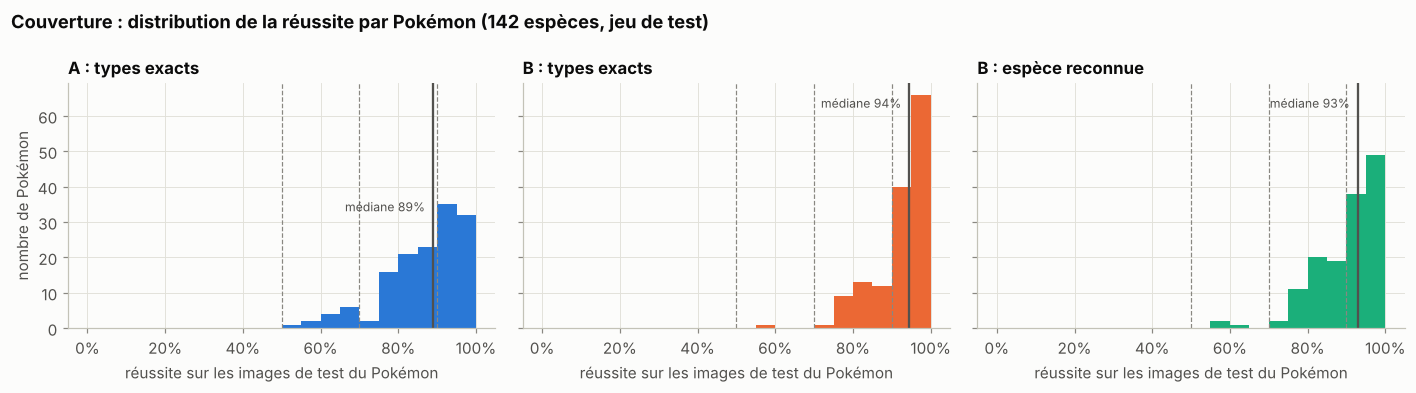

In [33]:
acc_types_B, cov_B = coverage((Yte == D_B).all(1), sp[te])
acc_types_A, cov_A = coverage((Yte == D_A).all(1), sp[te])
acc_esp_B, cov_esp = coverage(pred_B == sp[te], sp[te])
display(pd.DataFrame({"A : types (exact match)": cov_A, "B : types (exact match)": cov_B,
                      "B : espèce (top-1)": cov_esp}).T.map(lambda v: f"{v:.0%}"))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
bins = np.linspace(0, 1, 21)
for ax, (acc, titre, c) in zip(axes, [(acc_types_A, "A : types exacts", SERIES[0]),
                                       (acc_types_B, "B : types exacts", SERIES[1]),
                                       (acc_esp_B, "B : espèce reconnue", SERIES[2])]):
    ax.hist(acc, bins=bins, color=c, edgecolor="white")
    for s_ in (0.5, 0.7, 0.9):
        ax.axvline(s_, color=MUTED, ls="--", lw=0.8)
    ax.axvline(acc.median(), color=INK_2, lw=1.5)
    ax.text(acc.median() - 0.02, ax.get_ylim()[1] * 0.9, f"médiane {acc.median():.0%}", ha="right", fontsize=8, color=INK_2)
    ax.set(title=titre, xlabel="réussite sur les images de test du Pokémon")
    ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
axes[0].set_ylabel("nombre de Pokémon")
fig.suptitle("Couverture : distribution de la réussite par Pokémon (142 espèces, jeu de test)", x=0.01, ha="left",
             fontweight="bold")
fig.tight_layout()
save_fig(fig, "n2_17_couverture_histogrammes")
plt.show()

In [34]:
# Les 15 Pokémon les moins bien reconnus (approche B, espèce) et pourquoi
noms = pokemon.set_index("pokedex_number")["name"]
types_de = table_types.set_index("pokedex_number")
n_train = pd.Series(sp[tr]).value_counts()
lignes = []
for e in acc_esp_B.sort_values().index[:15]:
    m = sp[te] == e
    faux = pd.Series(pred_B[m][pred_B[m] != e]).value_counts()
    conf = int(faux.index[0]) if len(faux) else None
    meme_types = conf is not None and set(types_de.loc[e]) == set(types_de.loc[conf])
    lignee = conf is not None and abs(conf - e) <= 2 and types_de.loc[e, "type1"] == types_de.loc[conf, "type1"]
    raison = []
    if lignee:
        raison.append("confondu avec sa lignée d'évolution")
    elif conf is not None and types_de.loc[e, "type1"] == types_de.loc[conf, "type1"]:
        raison.append("confondu avec un Pokémon de même type")
    if n_train[e] < n_train.quantile(0.25):
        raison.append(f"peu d'images d'entraînement ({n_train[e]})")
    lignes.append({"Pokémon": noms[e], "réussite espèce": acc_esp_B[e], "types exacts": acc_types_B[e],
                   "images test": int(m.sum()), "images train": int(n_train[e]),
                   "souvent pris pour": f"{noms[conf]} ({faux.iloc[0]}×)" if conf else "-",
                   "mêmes types ?": "oui" if meme_types else "non",
                   "explication": " ; ".join(raison) or "styles d'images variés / autre"})
pires = pd.DataFrame(lignes).set_index("Pokémon")
pires.to_csv(ROOT_DIR / "reports" / "tables" / "pires_pokemon_test.csv")
pires.style.format({"réussite espèce": "{:.0%}", "types exacts": "{:.0%}"})

,réussite espèce,types exacts,images test,images train,souvent pris pour,mêmes types ?,explication
Pokémon,,,,,,,
Pidgeotto,60%,100%,15,73,Pidgeot (5×),oui,confondu avec sa lignée d'évolution
Slowbro,60%,60%,10,50,Tentacool (1×),non,confondu avec un Pokémon de même type ; peu d'images d'entraînement (50)
Abra,62%,75%,8,40,Machamp (1×),non,peu d'images d'entraînement (40)
Hitmonchan,71%,71%,14,69,Dugtrio (2×),non,styles d'images variés / autre
Golduck,72%,83%,18,83,Vaporeon (1×),oui,confondu avec un Pokémon de même type
Kadabra,75%,92%,12,57,Alakazam (2×),oui,confondu avec sa lignée d'évolution ; peu d'images d'entraînement (57)
Poliwrath,75%,75%,12,59,Poliwhirl (3×),non,confondu avec sa lignée d'évolution ; peu d'images d'entraînement (59)
Pidgeot,75%,88%,16,75,Fearow (1×),oui,confondu avec un Pokémon de même type
Dratini,75%,75%,16,73,Snorlax (1×),non,styles d'images variés / autre


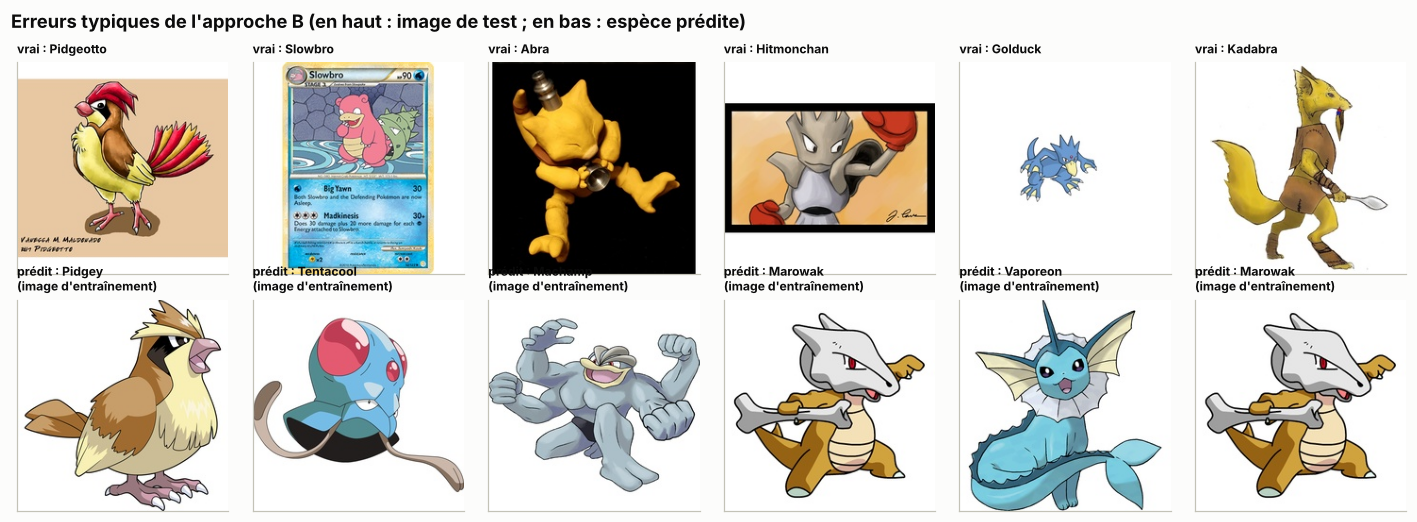

In [35]:
# Exemples d'erreurs : image de test mal reconnue / image d'entraînement de l'espèce prédite
cas = [e for e in acc_esp_B.sort_values().index[:6]]
fig, axes = plt.subplots(2, 6, figsize=(13, 4.8))
for j, e in enumerate(cas):
    idx = np.nonzero(te)[0][(sp[te] == e) & (pred_B != e)]
    if len(idx) == 0:
        continue
    i = idx[0]
    p = pred_B[np.searchsorted(np.nonzero(te)[0], i)]
    axes[0, j].imshow(X224[i]); axes[0, j].set_title(f"vrai : {noms[e]}", fontsize=8)
    ex_p = np.nonzero(tr & (sp == p))[0][0]
    axes[1, j].imshow(X224[ex_p]); axes[1, j].set_title(f"prédit : {noms[p]}\n(image d'entraînement)", fontsize=8)
for a in axes.flat:
    a.set_xticks([]); a.set_yticks([]); a.grid(False)
fig.suptitle("Erreurs typiques de l'approche B (en haut : image de test ; en bas : espèce prédite)", x=0.01, ha="left",
             fontweight="bold")
fig.tight_layout()
save_fig(fig, "n2_18_erreurs_typiques")
plt.show()

**Lecture : une couverture très large, et des erreurs qui s'expliquent**

- **Couverture sur le test :** avec l'approche B, **les 142 Pokémon** dépassent 50 % d'exact match sur les types, **99 %** dépassent 70 % et **74 %** dépassent 90 %. Pour l'espèce elle-même, ces taux sont de 100 %, 98 % et 60 %. La médiane de réussite par Pokémon est proche de 100 %.
  - L'approche A est un peu moins couvrante (100 %, 91 % et 46 % pour les types).
  - Aucun Pokémon n'est « oublié » par le modèle. C'est exactement l'exigence du sujet : de bonnes performances **sur le plus grand nombre de Pokémon**, et pas seulement sur les plus faciles.
- **Les 15 Pokémon les moins bien reconnus** le sont tout de même à 60–79 % en espèce. Trois causes se dégagent :
  1. **Une lignée d'évolution qui se ressemble.** Roucoups est pris pour Roucarnage ou Roucool, Kadabra pour Alakazam, Tartard pour Têtarte. L'erreur est alors souvent **sans conséquence sur les types** : Roucoups a 100 % de types exacts malgré 60 % en espèce, car toute sa lignée est Normal/Vol.
  2. **Peu d'images d'entraînement** : 40 pour Abra, 50 pour Flagadoss, contre une médiane d'environ 70.
  3. **Des images atypiques** : cartes à jouer, figurines, fan-arts dans un style très personnel, Pokémon minuscule ou dans une pose inhabituelle (voir la figure des erreurs typiques). Pour la plupart de ces Pokémon, les erreurs sont **dispersées** : 1 ou 2 confusions, chaque fois avec une espèce différente. C'est le signe d'images difficiles plutôt que d'une confusion systématique.
- **Les 9 Pokémon absents du dataset** (Nidoran♀/♂, Paras, Persian, Grolem, Grotadmorv, Onix, Krabby, Kabuto) ne peuvent pas être évalués. Avec l'approche B, ils seraient forcément mal identifiés. C'est une **limite de couverture des données**, pas du modèle, à signaler dans le rapport.

### 5.4 Performance et confusions par type

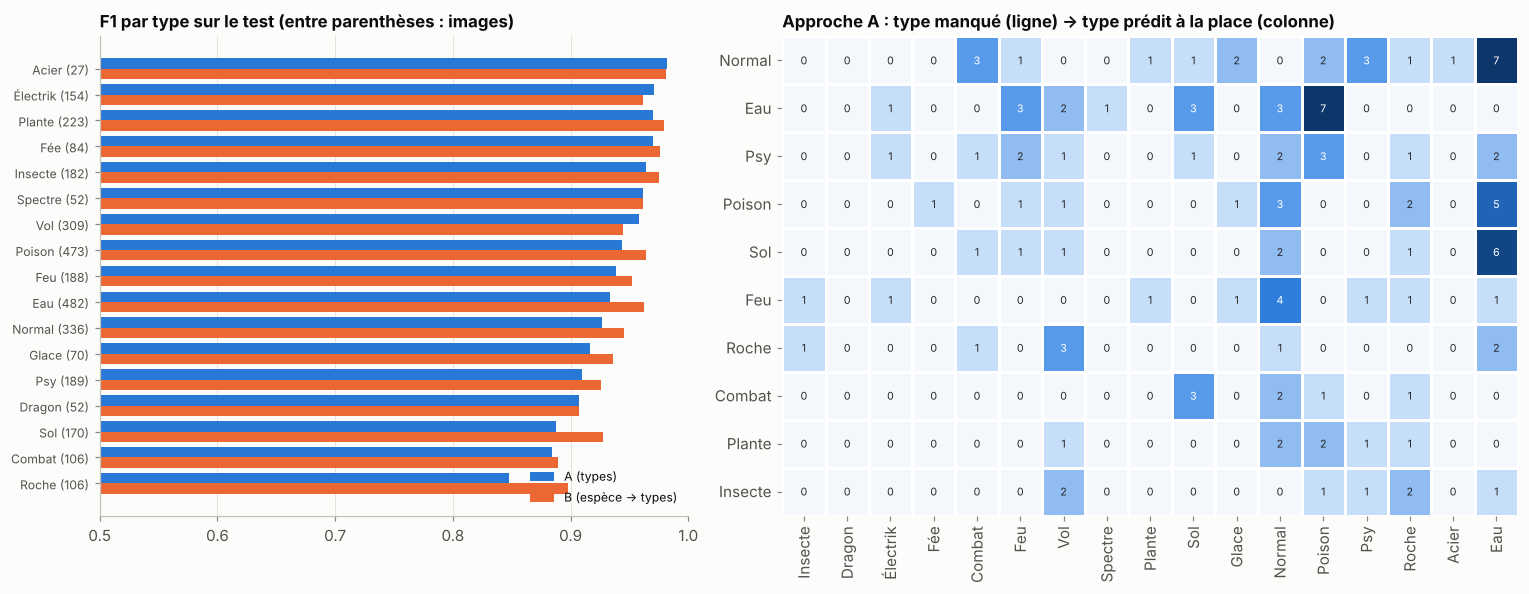

,Roche,Combat,Sol,Dragon,Psy,Glace,Normal,Eau,Feu,Poison,Vol,Spectre,Insecte,Fée,Plante,Électrik,Acier
A : F1,0.85,0.88,0.89,0.91,0.91,0.92,0.93,0.93,0.94,0.94,0.96,0.96,0.96,0.97,0.97,0.97,0.98
B : F1,0.90,0.89,0.93,0.91,0.93,0.94,0.95,0.96,0.95,0.96,0.94,0.96,0.98,0.98,0.98,0.96,0.98
A : rappel,0.81,0.93,0.88,0.85,0.90,0.94,0.93,0.95,0.94,0.94,0.96,0.96,0.96,0.95,0.96,0.96,1.00
A : précision,0.89,0.84,0.89,0.98,0.91,0.89,0.93,0.92,0.94,0.95,0.96,0.96,0.97,0.99,0.99,0.98,0.96
images de test,106.00,106.00,170.00,52.00,189.00,70.00,336.00,482.00,188.00,473.00,309.00,52.00,182.00,84.00,223.00,154.00,27.00


In [36]:
par_type = pd.DataFrame({
    "A : F1": f1_score(Yte, D_A, average=None, zero_division=0),
    "B : F1": f1_score(Yte, D_B, average=None, zero_division=0),
    "A : rappel": recall_score(Yte, D_A, average=None, zero_division=0),
    "A : précision": precision_score(Yte, D_A, average=None, zero_division=0),
    "images de test": Yte.sum(0).astype(int)}, index=[TYPE_FR[t] for t in TYPES_IMAGES]).sort_values("A : F1")

# « Quand le vrai type k est manqué, quel type est prédit à la place ? »
manque = np.zeros((K, K))
for i in range(len(Yte)):
    for k in np.nonzero((Yte[i] == 1) & (D_A[i] == 0))[0]:
        for j in np.nonzero((D_A[i] == 1) & (Yte[i] == 0))[0]:
            manque[k, j] += 1
noms_t = [TYPE_FR[t] for t in TYPES_IMAGES]
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw=dict(width_ratios=[1, 1.25]))
ax = axes[0]
yy = np.arange(len(par_type))
ax.barh(yy + 0.2, par_type["A : F1"], height=0.4, color=SERIES[0], label="A (types)")
ax.barh(yy - 0.2, par_type["B : F1"], height=0.4, color=SERIES[1], label="B (espèce → types)")
ax.set_yticks(yy, [f"{t} ({n})" for t, n in zip(par_type.index, par_type["images de test"])], fontsize=8)
ax.set(title="F1 par type sur le test (entre parenthèses : images)", xlim=(0.5, 1.0))
ax.legend(fontsize=8, loc="lower right")
ax.grid(axis="y", visible=False)
ax = axes[1]
ordre = np.argsort(-manque.sum(1))[:10]
sns.heatmap(pd.DataFrame(manque[ordre], index=[noms_t[k] for k in ordre], columns=noms_t), annot=True, fmt=".0f",
            cmap=CMAP_SEQ, linewidths=0.8, linecolor="white", annot_kws=dict(fontsize=7), cbar=False, ax=ax)
ax.set(title="Approche A : type manqué (ligne) → type prédit à la place (colonne)", xlabel="", ylabel="")
ax.grid(False)
fig.tight_layout()
save_fig(fig, "n2_19_types_test")
plt.show()
par_type.round(2).T

**Lecture**

- **Tous les types dépassent un F1 de 0,85 sur le test**, avec les deux approches. Sur des Pokémon **connus**, même les types rares sont bien reconnus : Acier atteint 0,98 avec seulement 27 images de test. Le modèle reconnaît Magnéti et Magnéton, et il en déduit Acier.
- **Les types les moins bien prédits sont Roche, Combat et Sol** (F1 de 0,85 à 0,89 en A). Ce sont des Pokémon souvent bruns ou gris, massifs, dont l'apparence se recoupe : Racaillou, Rhinocorne, Ossatueur, Tygnon…
- **B est meilleur que A pour presque tous les types.** Passer par l'espèce donne des types **cohérents** : une espèce correcte donne ses deux types d'un coup.
- **Quand A manque un type, il le remplace souvent par un type fréquent et visuellement « par défaut » :**
  - Normal manqué devient souvent **Eau**, et inversement ;
  - Eau devient **Poison** (les Tentacool et les Pokémon violets ou bleus) ;
  - Sol devient **Eau** (Pokémon bruns ou bleus photographiés près de l'eau, fonds aquatiques).
  
  Ce sont des confusions de **couleur dominante**, la faiblesse connue d'un modèle de types sans notion d'espèce.

### 5.5 Grad-CAM : que regarde le réseau ?

Un score élevé ne garantit pas que le modèle regarde **le Pokémon** : il pourrait s'appuyer sur un indice parasite, comme le fond, un texte ou un style de dessin. **Grad-CAM** (*Gradient-weighted Class Activation Mapping*) répond à cette question.

**Méthode.**
1. On calcule le gradient du score de la classe prédite $y^c$ par rapport aux cartes d'activation $A^k$ de la dernière couche convolutive. Pour EfficientNetB0, il y a 1 280 cartes de $7 \times 7$.
2. Chaque carte reçoit un poids $\alpha_k = \frac{1}{49} \sum_{i, j} \frac{\partial y^c}{\partial A^k_{ij}}$.
3. La carte de chaleur vaut $\mathrm{ReLU}\big(\sum_k \alpha_k A^k\big)$, agrandie à $224 \times 224$.

Les zones **chaudes** (en jaune) sont celles qui ont **fait monter** le score de la classe prédite.

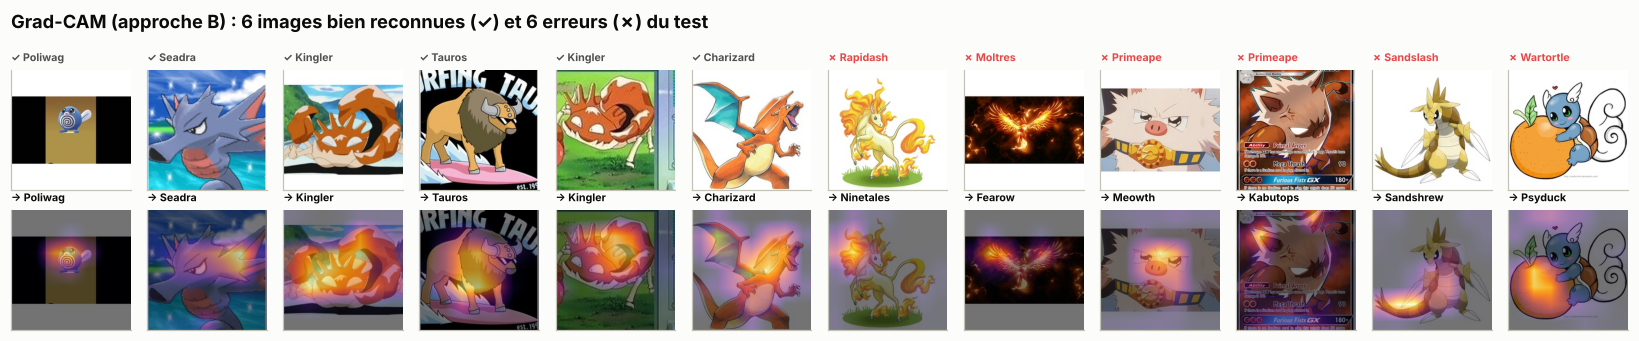

Part de l'attention sur le Pokémon : ['96%', '98%', '97%', '98%', '99%', '65%', '52%', '95%', '81%', '99%', '55%', '69%']
Surface occupée par le Pokémon     : ['57%', '95%', '74%', '93%', '100%', '43%', '38%', '57%', '70%', '98%', '28%', '43%']


In [37]:
idx_te = np.nonzero(te)[0]
ok = idx_te[pred_B == sp[te]]
ko = idx_te[pred_B != sp[te]]
rng = np.random.default_rng(RANDOM_STATE)
choix = np.r_[rng.choice(ok, 6, replace=False), rng.choice(ko, 6, replace=False)]
cams = grad_cam(modeles_finaux["B"], X224[choix])
pred_choix = cl_B[modeles_finaux["B"].predict(X224[choix].astype("float32"), verbose=0).argmax(1)]
fig, axes = plt.subplots(2, 12, figsize=(15, 3.2))
for j, (i, cam, p) in enumerate(zip(choix, cams, pred_choix)):
    axes[0, j].imshow(X224[i])
    axes[0, j].set_title(("✓ " if p == sp[i] else "✗ ") + noms[sp[i]], fontsize=7,
                         color=INK_2 if p == sp[i] else SERIES[7])
    axes[1, j].imshow(X224[i]); axes[1, j].imshow(cam, cmap="inferno", alpha=0.55, vmin=0, vmax=1)
    axes[1, j].set_title(f"→ {noms[p]}", fontsize=7)
for a in axes.flat:
    a.set_xticks([]); a.set_yticks([]); a.grid(False)
fig.suptitle("Grad-CAM (approche B) : 6 images bien reconnues (✓) et 6 erreurs (✗) du test", x=0.01, ha="left",
             fontweight="bold")
fig.tight_layout()
save_fig(fig, "n2_20_gradcam")
plt.show()

# Mesure globale : part de la « chaleur » qui tombe sur le Pokémon (pixels non blancs) plutôt que sur le fond
masque = X224[choix].min(axis=-1) < 235
part = [(c * m).sum() / c.sum() for c, m in zip(cams, masque)]
surf = [m.mean() for m in masque]
print("Part de l'attention sur le Pokémon :", [f"{p:.0%}" for p in part])
print("Surface occupée par le Pokémon     :", [f"{s_:.0%}" for s_ in surf])

In [38]:
# Sur un échantillon plus grand (200 images de test) : l'attention est-elle sur le Pokémon ?
ech = rng.choice(idx_te, 200, replace=False)
cams_e = np.concatenate([grad_cam(modeles_finaux["B"], X224[ech[k:k + 25]]) for k in range(0, 200, 25)])
masque_e = X224[ech].min(axis=-1) < 235
part_e = np.array([(c * m).sum() / max(c.sum(), 1e-8) for c, m in zip(cams_e, masque_e)])
surf_e = masque_e.mean(axis=(1, 2))
fond_blanc = surf_e < 0.9                      # images où il existe vraiment un fond blanc à distinguer
print(f"Images avec fond blanc ({fond_blanc.sum()}/200) : attention sur le Pokémon {np.median(part_e[fond_blanc]):.0%} "
      f"(médiane), alors que le Pokémon n'occupe que {np.median(surf_e[fond_blanc]):.0%} de l'image")

Images avec fond blanc (155/200) : attention sur le Pokémon 75% (médiane), alors que le Pokémon n'occupe que 46% de l'image


**Lecture : le modèle regarde bien le Pokémon**

- **Sur les images bien reconnues, la zone chaude couvre le corps du Pokémon,** et particulièrement ses **éléments distinctifs** : la tête et la spirale de Ptitard, les pinces de Krabboss, la crinière et les cornes de Tauros, la flamme de la queue de Dracaufeu. Le fond (herbe, mer, ciel) et le texte (titres, cartes) sont largement ignorés.
- **Mesure sur 200 images de test :** pour les 155 images où un fond blanc est présent, **75 % de l'« attention »** (en médiane) tombe sur le Pokémon, alors qu'il n'occupe que 46 % de l'image. Le modèle ne s'appuie donc **pas** sur un raccourci lié au fond ou au cadrage.
- **Les erreurs sont « compréhensibles » :**
  - Galopa est pris pour Feunard : deux quadrupèdes de feu à crinière flamboyante ;
  - Sulfura, sur fond noir et entouré de flammes, est pris pour Rapasdepic : même silhouette d'oiseau aux ailes déployées ;
  - Sablaireau est pris pour **sa pré-évolution** Sabelette ;
  - sur une **carte à jouer**, l'attention se disperse sur l'illustration et le texte, et le modèle se trompe.
  
  Le modèle regarde le bon endroit. Son erreur porte sur la **ressemblance** entre espèces.
- **Ce que cela implique pour la caméra (niveau 3) :** le Pokémon doit occuper une bonne partie du cadre, puisque l'appli recadre au centre. Les cartes et les écrans avec beaucoup de texte seront plus difficiles. Un seuil de confiance permettra de répondre « non reconnu » plutôt que de se tromper.

## 6. Choix final et sauvegarde

Cette partie relit les résultats sauvegardés par les parties 2 à 5 (`reports/tables/`, historiques d'entraînement, modèles candidats). On peut donc l'exécuter seule, sans tout réentraîner.

### 6.1 Tableau comparatif de tous les modèles

In [1]:
import sys, os, json, warnings
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from src.config import ROOT_DIR, MODELS_DIR
TAB = ROOT_DIR / "reports" / "tables"
HIST = TAB / "histories"
val = pd.read_csv(TAB / "recap_images_validation.csv").set_index(["approche", "modèle"])
test = pd.read_csv(TAB / "recap_images_test.csv").set_index("modèle")

# Coûts : temps d'entraînement, inférence par image, taille
def h(nom):
    return json.loads((HIST / f"{nom}.json").read_text(encoding="utf-8"))
cout = {
    ("B (espèce)", "CNN de zéro (96 px)"): (h("cnn_scratch_B")["train_time_s"], h("cnn_scratch_B")["infer_ms_per_image"], h("cnn_scratch_B")["size_mb"]),
    ("A (types)", "CNN de zéro (96 px)"): (h("cnn_scratch_A")["train_time_s"], h("cnn_scratch_A")["infer_ms_per_image"], h("cnn_scratch_A")["size_mb"]),
    ("B (espèce)", "EfficientNetB0 fine-tuné"): (h("efficientnet_b0_ft_B")["train_time_s"], h("efficientnet_b0_ft_B")["infer_ms_per_image"], None),
    ("A (types)", "EfficientNetB0 fine-tuné"): (h("efficientnet_b0_ft_A")["train_time_s"], h("efficientnet_b0_ft_A")["infer_ms_per_image"], None),
}
ms_gel = {"MobileNetV3-Small": 4.5, "MobileNetV3-Large": 10.6, "EfficientNetB0": 15.9, "ResNet50": 41.4}
mo_gel = {"MobileNetV3-Small": 4, "MobileNetV3-Large": 12, "EfficientNetB0": 16, "ResNet50": 94}
for (a, m) in val.index:
    if m.endswith("gelé"):
        b = m.replace(" gelé", "")
        cout[(a, m)] = (val.loc[(a, m), "durée (s)"], ms_gel[b], mo_gel[b])
comp = val[["top-1", "F1 micro", "exact match", "% Pokémon > 50 %", "% Pokémon > 90 %"]].copy()
comp["entraînement"] = [f"{cout[i][0] / 60:.0f} min" if i in cout and cout[i][0] > 120 else
                        (f"{cout[i][0]:.0f} s" if i in cout else f"{val.loc[i, 'durée (s)']:.0f} s") for i in comp.index]
comp["inférence (ms/image)"] = [f"{cout[i][1]:.1f}" if i in cout else "-" for i in comp.index]
comp = comp[~comp.index.get_level_values(1).str.startswith("Référence")]
comp.round(3)

top-1  F1 micro  exact match  \
approche   modèle                                                         
B (espèce) Régression logistique (C=0.01)  0.452     0.603        0.542   
           SVM RBF (ACP 128)               0.445     0.569        0.513   
           Random Forest (300 arbres)      0.510     0.672        0.610   
A (types)  Régression logistique (C=0.01)    NaN     0.490        0.306   
           SVM RBF (ACP 128)                 NaN     0.559        0.411   
           Random Forest (300 arbres)        NaN     0.453        0.265   
B (espèce) CNN de zéro (96 px)             0.796     0.872        0.847   
A (types)  CNN de zéro (96 px)               NaN     0.774        0.628   
B (espèce) MobileNetV3-Small gelé          0.810     0.882        0.860   
A (types)  MobileNetV3-Small gelé            NaN     0.701        0.497   
B (espèce) MobileNetV3-Large gelé          0.839     0.905        0.885   
A (types)  MobileNetV3-Large gelé            NaN     0.757        0.578   
B (espèce) EfficientNetB0 gelé             0.858     0.911        0.895   
A (types)  EfficientNetB0 gelé               NaN     0.783        0.613   
B (espèce) ResNet50 gelé                   0.855     0.918        0.898   
A (types)  ResNet50 gelé                     NaN     0.794        0.621   
B (espèce) EfficientNetB0 fine-tuné        0.908     0.951        0.938   
A (types)  EfficientNetB0 fine-tuné          NaN     0.933        0.872   

                                           % Pokémon > 50 %  % Pokémon > 90 %  \
approche   modèle                                                               
B (espèce) Régression logistique (C=0.01)             0.613             0.000   
           SVM RBF (ACP 128)                          0.514             0.014   
           Random Forest (300 arbres)                 0.697             0.021   
A (types)  Régression logistique (C=0.01)             0.190             0.007   
           SVM RBF (ACP 128)                          0.310             0.000   
           Random Forest (300 arbres)                 0.261             0.063   
B (espèce) CNN de zéro (96 px)                        0.993             0.415   
A (types)  CNN de zéro (96 px)                        0.641             0.070   
B (espèce) MobileNetV3-Small gelé                     1.000             0.387   
A (types)  MobileNetV3-Small gelé                     0.472             0.014   
B (espèce) MobileNetV3-Large gelé                     1.000             0.500   
A (types)  MobileNetV3-Large gelé                     0.634             0.007   
B (espèce) EfficientNetB0 gelé                        1.000             0.563   
A (types)  EfficientNetB0 gelé                        0.683             0.021   
B (espèce) ResNet50 gelé                              1.000             0.535   
A (types)  ResNet50 gelé                              0.725             0.042   
B (espèce) EfficientNetB0 fine-tuné                   1.000             0.754   
A (types)  EfficientNetB0 fine-tuné                   1.000             0.415   

                                          entraînement inférence (ms/image)  
approche   modèle                                                            
B (espèce) Régression logistique (C=0.01)         19 s                    -  
           SVM RBF (ACP 128)                      73 s                    -  
           Random Forest (300 arbres)            117 s                    -  
A (types)  Régression logistique (C=0.01)          4 s                    -  
           SVM RBF (ACP 128)                     173 s                    -  
           Random Forest (300 arbres)             57 s                    -  
B (espèce) CNN de zéro (96 px)                  92 min                  2.6  
A (types)  CNN de zéro (96 px)                  87 min                  3.3  
B (espèce) MobileNetV3-Small gelé                 35 s                  4.5  
A (types)  MobileNetV3-Small gelé                 25 s         

### 6.2 Le modèle retenu et pourquoi

**Modèle retenu : EfficientNetB0 pré-entraîné sur ImageNet, fine-tuné, approche B** (identification de l'espèce parmi 142, puis lecture des types dans `pokemon.csv`).

| Critère | B : EfficientNetB0 fine-tuné | A : EfficientNetB0 fine-tuné | Commentaire |
|---|---|---|---|
| Types exacts (test) | **0,938** | 0,878 | B est meilleur |
| F1 micro (test) | **0,951** | 0,936 | |
| **Couverture** : Pokémon > 90 % (test) | **74 %** | 46 % | critère central du sujet |
| Couverture : Pokémon > 70 % (test) | **99 %** | 91 % | |
| Donne le **nom** du Pokémon | **oui** | non | indispensable pour la caméra et la fiche du niveau 3 |
| Pokémon jamais vus | impossible | possible (exact match ≈ 0,3, réseau gelé) | seul avantage de A |
| Inférence (CPU) | environ 15 ms par image | environ 15 ms par image | compatible avec une appli en temps réel |
| Taille (sans l'optimiseur) | environ 19 Mo | environ 17 Mo | |

**Justification**

1. **Il est le meilleur sur toutes les métriques des Pokémon connus**, ce qui est le cas d'usage du Pokédex (142 espèces de la 1ʳᵉ génération).
2. **Sa couverture est la plus large** : aucun Pokémon n'est sous 60 % en espèce, 99 % des Pokémon dépassent 70 % de types exacts et 74 % dépassent 90 %. Il ne se contente pas des Pokémon faciles.
3. **Il donne l'espèce**, donc le nom, la fiche complète et des types **cohérents**, puisque ce sont ceux d'un vrai Pokémon.
4. **Il est léger (environ 19 Mo) et rapide sur CPU.** EfficientNetB0 fait aussi bien que ResNet50, qui est 6 fois plus gros.
5. **Les alternatives écartées :**
   - le **CNN de zéro** : moins bon, et 2 fois plus long à entraîner ;
   - les **réseaux gelés** : plus faibles que le réseau affiné ;
   - **ResNet50** : pas meilleur, mais 3 fois plus lent ;
   - la **référence classique** : très en dessous.

**Le modèle A est conservé comme « second avis »** dans l'appli, pour les types. C'est utile quand l'espèce est incertaine, ou pour un Pokémon absent des 142 espèces apprises. Sur un Pokémon jamais vu, il peut encore proposer un type plausible.

### 6.3 Sauvegarde

Les modèles candidats (`models/candidates/`) contiennent aussi l'**état de l'optimiseur** (moments d'AdamW), utile seulement pour reprendre l'entraînement. On les recharge **sans compilation**, puis on les sauvegarde allégés dans `models/` :
- `image_model.keras` : approche B, modèle retenu ;
- `image_model_types.keras` : approche A, second avis ;
- `image_classes.json` : la correspondance entre l'indice de classe, le numéro de Pokédex, le nom et les types ;
- `seuils_types.npy` (partie 5) : les seuils de décision par type de A.

In [2]:
import keras
import src.train_images                       # enregistre la loss personnalisée (WeightedBCE)
from src.train_images import CANDIDATES, PREDS
from src.image_utils import TYPES_IMAGES, load_splits
from src.preprocessing import load_clean

poke = load_clean().set_index("pokedex_number")
classes = h("efficientnet_b0_ft_B")["classes"]
meta = {"modele": "EfficientNetB0 (ImageNet) fine-tuné, 142 espèces de 1re génération",
        "entree": "image RGB 224 x 224, pixels 0-255, fond blanc, carré (src.image_utils.load_rgb + to_square)",
        "types": TYPES_IMAGES,
        "classes": [{"index": i, "pokedex_number": int(n), "name": poke.loc[n, "name"],
                     "type1": poke.loc[n, "type1"], "type2": poke.loc[n, "type2"]} for i, n in enumerate(classes)]}
(MODELS_DIR / "image_classes.json").write_text(json.dumps(meta, ensure_ascii=False, indent=1), encoding="utf-8")

for src_nom, dst in [("efficientnet_b0_ft_B", "image_model.keras"), ("efficientnet_b0_ft_A", "image_model_types.keras")]:
    m = keras.saving.load_model(CANDIDATES / f"{src_nom}.keras", compile=False)
    m.save(MODELS_DIR / dst)
    print(f"{dst} : {(MODELS_DIR / dst).stat().st_size / 1e6:.1f} Mo "
          f"(candidat avec optimiseur : {(CANDIDATES / f'{src_nom}.keras').stat().st_size / 1e6:.1f} Mo)")

I0000 00:00:1793908785.233347    2525 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1793908787.151350    2525 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


image_model.keras : 19.2 Mo (candidat avec optimiseur : 37.0 Mo)


image_model_types.keras : 17.3 Mo (candidat avec optimiseur : 33.8 Mo)


In [3]:
# Vérification : le modèle sauvegardé, rechargé par l'appli, redonne les mêmes prédictions sur le test
from src.pokedex_data import load_image_models, predict_image
splits = load_splits()
te_idx = np.nonzero((splits["split"] == "test").to_numpy())[0]
mods = load_image_models()
P_ref = np.load(PREDS / "efficientnet_b0_ft_B_test.npy")
ech = te_idx[:: len(te_idx) // 20][:20]
ok = 0
for i in ech:
    r = predict_image(mods, ROOT_DIR / splits.loc[i, "clean_path"])
    ok += r["top"][0]["index"] == int(P_ref[np.searchsorted(te_idx, i)].argmax())
print(f"Prédictions identiques à la partie 5 sur {ok}/{len(ech)} images de test")
r = predict_image(mods, ROOT_DIR / splits.loc[ech[0], "clean_path"])
print("Exemple :", splits.loc[ech[0], "name"], "→", [(t["name"], round(t["proba"], 3)) for t in r["top"][:3]],
      "| types (espèce) :", r["types_espece"], "| second avis A :", r["types_modele_A"])

Prédictions identiques à la partie 5 sur 20/20 images de test


Exemple : Abra → [('Abra', 1.0), ('Drowzee', 0.0), ('Raichu', 0.0)] | types (espèce) : ['psychic'] | second avis A : ['psychic']


**Bilan du niveau 2**

| | Résultat |
|---|---|
| Données | 14 715 images nettoyées, 142 espèces (9 Pokémon de 1ʳᵉ génération absents de l'archive). Doublons et conflits d'étiquettes retirés, types du CSV corrigés |
| Modèle retenu | **EfficientNetB0 fine-tuné, approche B** (espèce, puis types), avec le modèle A comme second avis pour les types |
| Test (Pokémon connus) | espèce : top-1 de 0,913, top-5 de 0,976. **Types exacts : 0,938** |
| Couverture (test) | **100 %** des Pokémon au-dessus de 50 %, **99 %** au-dessus de 70 %, **74 %** au-dessus de 90 % (types exacts) |
| Pokémon jamais vus (A, réseau gelé) | exact match d'environ 0,29 et au moins un type juste pour environ 60 % des images. Ce sont surtout les types visuellement cohérents (Acier, Fée, Feu, Spectre) qui se généralisent |
| Ce que regarde le modèle | le Pokémon lui-même (environ 75 % de l'attention Grad-CAM sur environ 46 % de la surface), pas le fond |
| Coût | environ 48 min de fine-tuning sur CPU, environ 15 ms par image, environ 18 Mo |
| Fichiers pour l'appli | `models/image_model.keras`, `models/image_model_types.keras`, `models/image_classes.json`, `models/seuils_types.npy` |

**Limites et pistes d'amélioration**
- Fine-tuner sur train + validation réunis (environ +1 point attendu).
- Faire le test sur des Pokémon jamais vus avec un modèle affiné.
- Ajouter des images pour les 9 Pokémon manquants.
- Utiliser des images plus grandes, ou un réseau plus gros sur GPU.
- Tester en conditions réelles avec la caméra (niveau 3).

## 7. Préparer la caméra (niveau 3) : seuil de confiance et images de référence

Devant la caméra, l'utilisateur peut présenter un Pokémon que le modèle **ne connaît pas** : l'un des 9 absents, un Pokémon d'une autre génération, ou n'importe quel objet. Il peut aussi présenter une image **difficile** (reflets, flou, cadrage). Un modèle softmax donne **toujours** une réponse, puisque ses probabilités somment à 1. Pour éviter d'afficher une mauvaise fiche, on n'accepte la réponse que si la **probabilité maximale** dépasse un **seuil de confiance** $\tau$. Sinon, l'appli affiche « Pokémon non reconnu ».

### 7.1 Choix du seuil sur la validation

**Le compromis.** Plus $\tau$ est haut, plus les réponses acceptées sont **fiables**, mais plus on rejette de **bonnes** réponses. C'est la courbe « risque–couverture » de la *classification sélective*.

I0000 00:00:1793956126.288382     731 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1793956127.575367     731 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


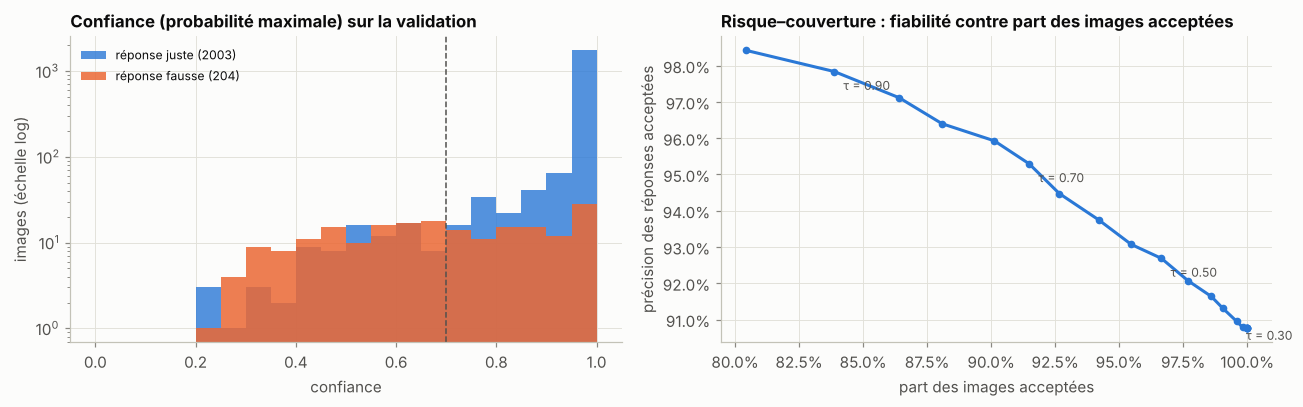

Seuil retenu (gain net maximal) : τ = 0.7


,part acceptée,précision des réponses acceptées,erreurs évitées,bonnes réponses perdues,gain net
seuil,,,,,
0.30,0.996,0.909,5,4,1
0.35,0.990,0.913,14,7,7
0.40,0.986,0.916,22,9,13
0.45,0.977,0.921,33,18,15
0.50,0.966,0.927,48,26,22
0.55,0.955,0.931,58,42,16
0.60,0.942,0.937,74,54,20
0.65,0.927,0.945,91,71,20
0.70,0.915,0.953,109,79,30


In [1]:
import sys, os, json, warnings
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.config import ROOT_DIR, MODELS_DIR, RANDOM_STATE
from src.viz import set_style, save_fig, SERIES, INK_2, MUTED
from src.image_utils import load_splits
from src.train_images import PREDS
set_style()

splits = load_splits()
va = (splits["split"] == "val").to_numpy()
classes = np.array([c["pokedex_number"] for c in
                    json.loads((MODELS_DIR / "image_classes.json").read_text(encoding="utf-8"))["classes"]])
P = np.load(PREDS / "efficientnet_b0_ft_B_val.npy")
conf = P.max(1)
juste = classes[P.argmax(1)] == splits["pokedex_number"].to_numpy()[va]

seuils = np.round(np.arange(0.0, 1.0, 0.05), 2)
courbe = pd.DataFrame({"seuil": seuils,
                       "part acceptée": [(conf >= t).mean() for t in seuils],
                       "précision des réponses acceptées": [juste[conf >= t].mean() for t in seuils],
                       "erreurs évitées": [int((~juste & (conf < t)).sum()) for t in seuils],
                       "bonnes réponses perdues": [int((juste & (conf < t)).sum()) for t in seuils]})
courbe["gain net"] = courbe["erreurs évitées"] - courbe["bonnes réponses perdues"]
TAU = float(courbe.loc[courbe["gain net"].idxmax(), "seuil"])

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
ax = axes[0]
bins = np.linspace(0, 1, 21)
ax.hist(conf[juste], bins=bins, color=SERIES[0], alpha=0.8, label=f"réponse juste ({juste.sum()})", edgecolor="white")
ax.hist(conf[~juste], bins=bins, color=SERIES[1], alpha=0.85, label=f"réponse fausse ({(~juste).sum()})", edgecolor="white")
ax.set_yscale("log")
ax.axvline(TAU, color=INK_2, ls="--", lw=1)
ax.set(title="Confiance (probabilité maximale) sur la validation", xlabel="confiance", ylabel="images (échelle log)")
ax.legend(fontsize=8, loc="upper left")
ax = axes[1]
ax.plot(courbe["part acceptée"], courbe["précision des réponses acceptées"], marker="o", ms=4, color=SERIES[0])
for _, r in courbe[courbe["seuil"].isin([0.3, 0.5, TAU, 0.9])].iterrows():
    ax.annotate(f"τ = {r['seuil']:.2f}", (r["part acceptée"], r["précision des réponses acceptées"]),
                xytext=(6, -12), textcoords="offset points", fontsize=8, color=INK_2)
ax.set(title="Risque–couverture : fiabilité contre part des images acceptées",
       xlabel="part des images acceptées", ylabel="précision des réponses acceptées")
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
fig.tight_layout()
save_fig(fig, "n2_21_seuil_confiance")
plt.show()
print(f"Seuil retenu (gain net maximal) : τ = {TAU}")
courbe[courbe["seuil"].between(0.3, 0.95)].round(3).set_index("seuil")

In [2]:
meta = json.loads((MODELS_DIR / "image_classes.json").read_text(encoding="utf-8"))
meta["seuil_confiance"] = TAU
meta["seuil_confiance_justification"] = ("probabilité maximale minimale pour accepter une réponse ; choisie sur la "
                                          "validation (gain net : erreurs évitées - bonnes réponses perdues maximal)")
(MODELS_DIR / "image_classes.json").write_text(json.dumps(meta, ensure_ascii=False, indent=1), encoding="utf-8")
print("Seuil enregistré dans models/image_classes.json")

Seuil enregistré dans models/image_classes.json


### 7.2 Une image de référence par Pokémon

La fiche affichée par l'appli montre une **image de référence** du Pokémon reconnu. Les 14 715 images ne sont pas dans git, car elles sont trop lourdes. On en extrait donc **une par espèce**, de 160 × 160 pixels, dans `assets/reference/`, soit environ 1 Mo au total.

**Choix automatique.** Parmi les images **d'entraînement** de chaque espèce, on prend celle qui maximise la somme de quatre critères :
- la probabilité que le modèle donne à la bonne espèce, ce qui garantit une image **typique** ;
- la part de **fond blanc** sur les bords, qui favorise un artwork propre plutôt qu'une capture ou une carte ;
- un bonus si l'original était un **PNG transparent**, car les artworks officiels sont détourés ;
- la **saturation** moyenne des couleurs, qui écarte les dessins au trait et les coloriages.

142 images de référence écrites dans assets/reference/ (1.0 Mo)


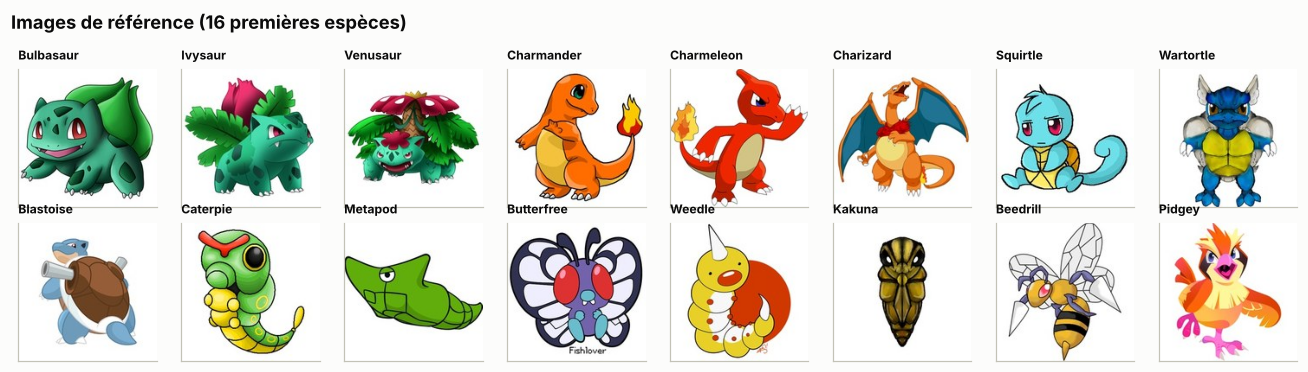

In [3]:
from PIL import Image
from src.train_images import load_arrays, make_dataset, targets
from src.pokedex_data import load_image_models

tr = (splits["split"] == "train").to_numpy()
X = load_arrays(224)
mods = load_image_models(with_types=False)
y, _ = targets(splits, "B")
P_tr = mods.species.predict(make_dataset(X[tr], y[tr], 64, False), verbose=0)
idx_tr = np.nonzero(tr)[0]
p_vraie = P_tr[np.arange(len(idx_tr)), y[tr]]
bord = np.concatenate([X[idx_tr][:, :12].reshape(len(idx_tr), -1, 3), X[idx_tr][:, -12:].reshape(len(idx_tr), -1, 3),
                       X[idx_tr][:, :, :12].reshape(len(idx_tr), -1, 3), X[idx_tr][:, :, -12:].reshape(len(idx_tr), -1, 3)], 1)
blanc = (bord.min(axis=2) >= 240).mean(1)
# Bonus « artwork officiel » : PNG transparent à l'origine (détouré) et couleurs saturées (pas un dessin au trait)
from src.image_utils import IMAGES_INDEX
transp = splits["path"].map(pd.read_csv(IMAGES_INDEX).set_index("path")["transparency"]).fillna(False).to_numpy()[tr]
Xs = X[idx_tr][:, ::4, ::4].astype(np.float32)                       # sous-échantillonnage pour aller vite
mx, mn = Xs.max(-1), Xs.min(-1)
sat = np.where(mx > 0, (mx - mn) / np.maximum(mx, 1), 0)
fg = mn < 235
saturation = (sat * fg).sum((1, 2)) / np.maximum(fg.sum((1, 2)), 1)
score = p_vraie + 0.5 * blanc + 0.5 * transp.astype(float) + 0.5 * saturation

REF = ROOT_DIR / "assets" / "reference"
REF.mkdir(parents=True, exist_ok=True)
choix = pd.DataFrame({"i": idx_tr, "esp": splits["pokedex_number"].to_numpy()[tr], "score": score}) \
          .sort_values("score", ascending=False).drop_duplicates("esp")
for _, r in choix.iterrows():
    Image.fromarray(X[int(r["i"])]).resize((160, 160), Image.LANCZOS).save(REF / f"{int(r['esp']):03d}.jpg", quality=88)
taille = sum(f.stat().st_size for f in REF.glob("*.jpg")) / 1e6
print(f"{len(choix)} images de référence écrites dans assets/reference/ ({taille:.1f} Mo)")

ex = choix.sort_values("esp").head(16)
fig, axes = plt.subplots(2, 8, figsize=(12, 3.4))
noms = splits.drop_duplicates("pokedex_number").set_index("pokedex_number")["name"]
for a, (_, r) in zip(axes.flat, ex.iterrows()):
    a.imshow(Image.open(REF / f"{int(r['esp']):03d}.jpg")); a.set_title(noms[int(r["esp"])], fontsize=8)
    a.set_xticks([]); a.set_yticks([]); a.grid(False)
fig.suptitle("Images de référence (16 premières espèces)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save_fig(fig, "n2_22_images_reference")
plt.show()

**Lecture**

- **Le modèle est trop confiant quand il se trompe.** Sur la validation, ses réponses justes ont presque toutes une confiance proche de 100 %, mais ses **erreurs** ont encore une confiance médiane d'environ 68 %. La confiance permet donc de séparer **en partie** les bonnes réponses des mauvaises, pas complètement.
- **Seuil retenu : τ = 0,7.**
  - C'est le seuil qui maximise le gain net, c'est-à-dire les erreurs évitées moins les bonnes réponses perdues.
  - Il fait passer la précision des réponses acceptées de 91 % à **environ 95 %**, en n'écartant qu'environ 8 % des images. Plus de la moitié des erreurs sont alors remplacées par « Pokémon non reconnu ».
- **Ce seuil a été choisi sur des images du dataset.** Devant une caméra (reflets, flou, perspective, fond), les confiances seront plus basses, donc l'appli répondra plus souvent « non reconnu ». C'est ce que mesurera le test réel du niveau 3.
- **Un objet qui n'est pas un Pokémon** obtient en général une confiance faible, mais **rien ne le garantit**. Un modèle softmax n'a jamais vu d'exemple « autre » pendant l'entraînement. Pour aller plus loin, on pourrait ajouter une classe « pas un Pokémon », entraînée sur des images quelconques, ou utiliser une méthode de détection d'images hors distribution.
- **Images de référence :** une image typique par espèce, choisie automatiquement parmi les images d'entraînement, pèse 0,7 Mo au total. Elle est affichée dans la fiche de l'appli.